#### Cartesian motion executor -> real `FFW SG2`

`sim_motion_executor_cartesian_test.ipynb` wired to the hardware. A whole-arm move is
**planned as a straight line for the wrist and played back one position command per control
tick**; every tick published to the robot is one sample of that plan.

The planner and the executor class are byte-identical to the simulation notebook, so a
sequence that was checked there is the same sequence here. What this notebook adds is the
real plumbing (`q_msg_layout`, ZMQ pub/sub, the OFF/ON gate) and the safety work that only
matters on hardware.

Run order:
1. `real_render_MetaQuest3_sg2.ipynb` in another kernel/window (optional, shows real vs command).
2. This notebook, top to bottom. **Do not skip the offline check** -- it is the only chance to
   see a plan before the robot executes it.
3. `Robot` starts at `OFF`. Switch it to `ON` only after the gizmos sit on the wrists.
4. Pick a command in the `Motion` row.

| row | what it does |
|---|---|
| `Robot` | `OFF` = nothing is published / `ON` = re-reads the real robot state, cancels anything running, then publishes every tick |
| `Motion` | `bring_up` / `grip_close` / `grip_open` / `shut_down` / `stop` = cancel where it is |
| `Preset` | `zero` / `init` -- routed through the executor, so a preset is a planned move / `sync` cancels and re-seeds the gizmos |
| `File` | `save` / `load` the pose as `qpos/sg2_joint_qpos.json` (a load is executed, not jumped) |
| `Collision` | signed-distance warning, **report only** -- nothing is corrected and nothing is stopped |
| `EEF` | draw both wrist frames and print position / RPY |
| `Show` | which wrist gizmo stays live |

**Three things keep the hardware safe, and they are the reason to prefer this over dragging
gizmos by hand:**

1. **The per-tick step is bounded by the plan itself.** `estimate_duration` returns the shortest
   `T` that respects `v_max`, so the largest change between two consecutive published messages is
   `v_max / robot_hz` -- 0.6 deg at full scale, 0.18 deg at `REAL_SPEED_SCALE = 0.3`. Dragging a
   gizmo has no such bound: `real_eef_controller_sg2_teleop.ipynb` can emit up to 64 deg in one
   tick if the target jumps, and is safe only because a human hand moves slowly.
2. **A slow loop makes the motion longer, never faster.** The executor advances by *index*, not by
   clock. A stalled pass emits one fewer message; it never skips ahead.
3. **`Robot` OFF -> ON re-reads the robot.** The simulation runs open-loop while the robot is off,
   so the gap at the moment of switching on is exactly the step the robot would be asked to take
   on the first message. That transition re-reads the real state, refuses if the gap exceeds
   `MAX_ON_DRIFT_RAD`, and re-seeds the executor and the gizmos from it.

**What is NOT protected.** The collision check is report-only, here as in simulation. The scene
merged below is floor + robot, so it knows nothing about the table the real robot stands at --
clear the workspace before running `bring_up` or `shut_down`.

**셀 1. 프로젝트 초기화 및 모듈 임포트**

프로젝트 초기화 스크립트(`init_project.py`)를 실행하고 시뮬레이션/키네마틱스/유틸리티/Qt 패키지를 임포트한다. `real_eef_controller_sg2_teleop.ipynb`와 비교해 네 가지가 추가된다: Cartesian 경로를 C2 스플라인으로 맞추는 `scipy.interpolate.CubicSpline`, 관절 속도 상한과 `apply_sg2_joint_rate_limit`이 들어 있는 `package.joint_marker_real`, min-jerk 플래너와 `SG2MotionExecutor`와 bring-up 웨이포인트가 들어 있는 `package.motion_executor`, 그리고 오버레이 텍스트 헬퍼가 있는 `package.joint_control`. 마지막으로 Qt 애플리케이션 인스턴스(`app`)를 생성한다.

In [1]:
%run ../package/init_project.py

import numpy as np
from scipy.interpolate import CubicSpline   # C2 path fit for the Cartesian planner

from ri_motion_v5_package.init_scripts.init_ipython_setup import *
from ri_motion_v5_package.init_scripts.init_qt import *
from ri_motion_v5_package.mujoco_sim import *
from ri_motion_v5_package.kinematics import *
from ri_motion_v5_package.utility import *
from ri_motion_v5_package.qt import *
from utils import *
from package.joint_control import *        # not `from joint_control import *`: IPython's %run puts
from package.joint_marker_control import * # PACKAGE_DIR on sys.path only during the run
from package.joint_marker_real import *    # speed limits + apply_sg2_joint_rate_limit
from package.motion_executor import *      # min-jerk planner, SG2MotionExecutor, bring-up waypoints

app = get_qt_app()


[ffw_sg2_vr_teleoperation] initialized.
 - PROJECT_DIR: /Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation
Basic packages initialized.
 import numpy as np
 import matplotlib.pyplot as plt
 import scipy as sp
 from PIL import Image
[ipython] settings (retina, inline, qt) initialized.
[numpy] settings initialized.
[matplotlib] settings initialized.
[qt] package initialized.


**셀 2. 충돌 인식(collision-aware) IK 네이티브 백엔드 빌드**

부호 거리(signed distance) 계산용 네이티브 백엔드를 빌드(또는 로드)한다. `required=True`이므로 실패하면 예외가 발생한다. 이 노트북에서 백엔드는 두 곳에서 쓰인다 — executor가 idle일 때의 기즈모 충돌 인식 IK, 그리고 셀 8의 오프라인 경로 스윕. 후자는 계획된 궤적 전체를 순수 파이썬 경로로 훑으므로 네이티브 백엔드가 없으면 눈에 띄게 느려진다.

In [2]:
native_backend = build_sg2_collision_aware_ik_backend(
    clean   = False,
    verbose = True,
    required = True,)
print("bind info:",native_backend.native_info())

[build_native]
  module      : _mujoco_collision_aware_ik_bind
  output      : mujoco_sim/so/_mujoco_collision_aware_ik_bind.cpython-310-darwin.so
  compiler    : clang++
  project cpp:
    [01] mujoco_sim/cpp/bindings.cpp
    [02] mujoco_sim/cpp/signed_distance_bindings.cpp
    [03] mujoco_sim/cpp/signed_distance.cpp
    [04] mujoco_sim/cpp/ik_bindings.cpp
    [05] mujoco_sim/cpp/ik.cpp
  project hpp:
    [01] mujoco_sim/cpp/signed_distance_bindings.hpp
    [02] mujoco_sim/cpp/signed_distance.hpp
    [03] mujoco_sim/cpp/ik_bindings.hpp
    [04] mujoco_sim/cpp/ik.hpp
    [05] mujoco_sim/cpp/mujoco_handles.hpp
  defines:
    [01] RI_NATIVE_ENABLE_SIGNED_DISTANCE
    [02] RI_NATIVE_ENABLE_IK
    [03] RI_NATIVE_MODULE_NAME=_mujoco_collision_aware_ik_bind
  nanobind cpp:
    [01] nanobind/src/nb_combined.cpp
  commands    : hidden; pass show_commands=True to print full commands
[build_native] compile
  [01/06] mujoco_sim/cpp/bindings.cpp -> build/native/bindings.o
  [02/06] mujoco_sim/cpp/

**셀 3. 통신(ZMQ) 포트/IP 설정 및 안전 파라미터**

렌더러 퍼블리시 포트(`RENDER_PORT`), 실제 SG2로 명령을 보낼 포트/IP(`PUB_TO_SG2_PORT`, `PUB_TO_SG2_IP`), SG2 상태를 구독할 포트/IP(`SUB_FROM_SG2_PORT`, `SUB_FROM_SG2_IP`)를 정의한다. `ALLOW_MISSING_ROBOT_STATE`는 로봇 상태 수신 실패를 허용할지 결정한다.

여기에 실기 전용 안전 노브 두 개가 추가된다.

- **`REAL_SPEED_SCALE`** — 모든 속도/가속도 상한에 곱해지는 배율. **단 한 곳(executor의 limits)에만 적용되고, 그 값이 곧 `apply_sg2_joint_rate_limit`이 클램프하는 값**이므로 계획과 클램프가 어긋날 수 없다. 0.3에서 시작해 `bring_up` / `shut_down`을 끝까지 지켜본 뒤 올린다.
- **`MAX_ON_DRIFT_RAD`** — `Robot`을 OFF에서 ON으로 올릴 때 허용하는 시뮬레이션-실기 간 최대 오차. 로봇이 OFF인 동안 시뮬레이션은 open-loop로 돌아가므로, ON 순간의 이 간격이 곧 로봇이 첫 메시지에서 밟게 될 계단 크기다. 초과하면 ON을 거부한다.

In [3]:
RENDER_PORT = 5556
PUB_TO_SG2_PORT = 5561
PUB_TO_SG2_IP = get_ip_address()
SUB_FROM_SG2_PORT = 5560
SUB_FROM_SG2_IP = "192.168.6.2"

ALLOW_MISSING_ROBOT_STATE = False

# ---------------------------------------------------------------------------
# Safety knobs -- read these before running anything
# ---------------------------------------------------------------------------
# Every ceiling in this notebook is multiplied by REAL_SPEED_SCALE, and it is
# applied in ONE place (the executor's limits, which are also what the rate limit
# clamps against) so the plan and the clamp can never disagree. Start at 0.3,
# watch a full bring_up / shut_down, then raise it.
#
# 2.0 = 120 deg/s on the arm joints, 0.30 m/s at the wrist. Raised from 0.5 as a
# deliberate step up, NOT as a validated ceiling: nothing here has been checked
# against the DY-80 / DY-70 / DP-42 specs (see SG2_JOINT_ACC_RAMP_SEC, still
# PROVISIONAL). Watch the analysis cell after the next bring_up -- if the rate
# limit engages or the tracking error grows, come back down before going higher.
REAL_SPEED_SCALE = 1.0

# How far the simulation may have drifted from the real robot before an OFF->ON
# transition is refused. The sim runs open-loop while the robot is OFF, so the
# gap at the moment of switching on is exactly the step the robot would be asked
# to take on the first published message.
MAX_ON_DRIFT_RAD = np.deg2rad(10.0)

print("PUB_TO_SG2_IP",PUB_TO_SG2_IP)
print("Robot state SUB: tcp://%s:%d"%(SUB_FROM_SG2_IP,SUB_FROM_SG2_PORT))
print("REAL_SPEED_SCALE %.2f -> revolute %.1f deg/s, prismatic %.3f m/s"%(
    REAL_SPEED_SCALE,
    np.rad2deg(SG2_MAX_REV_JOINT_SPEED)*REAL_SPEED_SCALE,
    SG2_MAX_PRI_JOINT_SPEED*REAL_SPEED_SCALE,))
print("OFF->ON drift limit: %.1f deg"%np.rad2deg(MAX_ON_DRIFT_RAD))

PUB_TO_SG2_IP 192.168.6.100
Robot state SUB: tcp://192.168.6.2:5560
REAL_SPEED_SCALE 1.00 -> revolute 60.0 deg/s, prismatic 0.050 m/s
OFF->ON drift limit: 10.0 deg


**셀 4. MuJoCo 시뮬레이션 환경 로드**

바닥(`FLOOR_XML_PATH`)과 SG2 로봇(`SG2_XML_PATH`) MJCF를 병합해 씬 XML(`SG2_SCENE_XML_PATH`)을 만들고 `MuJoCoParser` 환경(`env`)을 생성한다.

`sim_motion_executor_cartesian_test.ipynb`와 달리 `table.xml`을 넣지 않는다 — 실제 로봇이 서 있는 책상은 이 모델에 없다. 따라서 **셀 8의 충돌 스윕과 루프의 충돌 경고는 자기충돌만 본다.** 실행 전에 작업 공간을 비워야 한다.

In [4]:
xml_path = merge_mjcfs(
    included_mjcf_files = [
        str(FLOOR_XML_PATH),
        str(SG2_XML_PATH),
    ],
    output_xml_path = str(SG2_SCENE_XML_PATH),)
env = MuJoCoParser(rel_xml_path=xml_path,verbose=False)

[merge_mjcfs] Merging [2] MJCF files:
  - [0] [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/floor_simple_white.xml]
  - [1] [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/ffw_sg2.xml]
[merge_mjcfs] Saved merged XML to:[/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/scene_ffw_sg2_metaquest3.xml]
MuJoCo model loaded from [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/scene_ffw_sg2_metaquest3.xml].


**셀 5. 관절 메시지 레이아웃 구성 및 실제 로봇 초기 자세 동기화**

환경을 리셋하고 베이스 위치를 세팅한 뒤, 실제 로봇으로 보낼 명령 관절 목록(`command_joint_names`)과 각 관절 그룹(lift/head/arm_l/arm_r/gripper_l/gripper_r)을 메시지 필드로 매핑하는 `q_msg_layout`을 만든다. 관절 최소/최대값(`q_use_min`, `q_use_max`)도 조회한다.

이후 SG2로부터 현재 관절 상태를 구독(`get_latest_robot_qpos`)해 시뮬레이션 자세를 실제 로봇 자세에 맞춘다. **이 노트북에서는 이 동기화가 특히 중요하다.** executor는 각 세그먼트를 "직전에 도달한 자세"(`self.q_use`)에서 계획하므로, 시작 자세가 로봇과 다르면 첫 세그먼트 전체가 잘못된 지점에서 계획된다. 셀 10의 `executor.q_use = q_use.copy()`가 그 값을 executor에 심어 준다.

In [5]:
env.reset()
env.set_p("base_link","body",(0.0,0.0,0.01))

real_command_joint_names = (
    list(SG2_REAL_COMMAND_JOINT_NAMES)
    + [SG2_GRIPPER_DRIVER_JOINT_NAMES[hand_type] for hand_type in SG2_HAND_TYPES]
)
command_joint_names = filter_existing_joint_names(env,real_command_joint_names)
q_msg_format_dict = {
    "lift"      : {"prefixes":["lift_joint"]},
    "head"      : {"prefixes":["head_joint"]},
    "arm_l"     : {"prefixes":["arm_l_joint"]},
    "arm_r"     : {"prefixes":["arm_r_joint"]},
    "gripper_l" : {"prefixes":["gripper_l_joint1"]},
    "gripper_r" : {"prefixes":["gripper_r_joint1"]},
}
q_msg_layout = build_q_msg_layout(
    env               = env,
    q_msg_format_dict = q_msg_format_dict,
    use_joint_names   = command_joint_names,)
q_use_min = env.get_joint_mins(command_joint_names)
q_use_max = env.get_joint_maxs(command_joint_names)

print("Joint message layout")
print("--------------------")
for q_msg_key in q_msg_layout["q_msg_keys"]:
    joint_names = q_msg_layout["qmsgkeys_to_usejointnames_dict"][q_msg_key]
    joint_idxs = q_msg_layout["qmsgkeys_to_usejointidxs_dict"][q_msg_key]
    print("%-8s | %2d joints | idxs:%s | %s"%(q_msg_key,len(joint_names),joint_idxs,joint_names))
print("--------------------")
print("%-8s | %2d joints"%("total",len(command_joint_names)))
print("unused:",q_msg_layout["unused_joint_names"])

try:
    q_use,recv_count = get_latest_robot_qpos(
        env             = env,
        q_msg_layout    = q_msg_layout,
        use_joint_names = command_joint_names,
        sub_ip          = SUB_FROM_SG2_IP,
        sub_port        = SUB_FROM_SG2_PORT,
        timeout_sec     = 1.0,
        verbose         = True,)
    print("[Robot init] OK. recv_count:[%d]"%recv_count)
except Exception:
    if not ALLOW_MISSING_ROBOT_STATE:
        raise
    q_use = env.get_qpos(joint_names=command_joint_names)
    print("[Robot init] missing robot state; using current MuJoCo q because ALLOW_MISSING_ROBOT_STATE=True.")

# Start the sim at the real robot pose so the gizmos seed without a jump.
q_use = np.clip(q_use,q_use_min,q_use_max)
env.forward(q=q_use,joint_names=command_joint_names)

Joint message layout
--------------------
lift     |  1 joints | idxs:[0] | ['lift_joint']
head     |  2 joints | idxs:[1, 2] | ['head_joint1', 'head_joint2']
arm_l    |  7 joints | idxs:[3, 4, 5, 6, 7, 8, 9] | ['arm_l_joint1', 'arm_l_joint2', 'arm_l_joint3', 'arm_l_joint4', 'arm_l_joint5', 'arm_l_joint6', 'arm_l_joint7']
arm_r    |  7 joints | idxs:[10, 11, 12, 13, 14, 15, 16] | ['arm_r_joint1', 'arm_r_joint2', 'arm_r_joint3', 'arm_r_joint4', 'arm_r_joint5', 'arm_r_joint6', 'arm_r_joint7']
gripper_l |  1 joints | idxs:[17] | ['gripper_l_joint1']
gripper_r |  1 joints | idxs:[18] | ['gripper_r_joint1']
--------------------
total    | 19 joints
unused: []
[ZMQ Subscriber] pid:[33550] endpoint:[tcp://192.168.6.2:5560]
[ZMQ] role:[sub] ip:[192.168.6.2] port:[5560] hwm:[1] conflate:[True]
[ZMQ SUB] pid:[33550] Socket closed.
[Robot init] OK. recv_count:[70]


**셀 6. IK 솔버 두 벌, 충돌 후보 쌍, 스케일된 관절 상한**

이 노트북은 **성격이 다른 두 가지 IK**를 쓰기 때문에 솔버를 두 벌 만든다.

- `ik_solvers` — `create_sg2_arm_ik_solvers`가 만드는 팔별 독립 DLS 솔버. `plan_cartesian_wrist`가 경로 위 각 knot에서, 그리고 `shut_down`의 손목 리프트 사전 단계가 쓴다. `sim_motion_executor_cartesian_test.ipynb`와 **동일한 솔버**이므로 시뮬레이션에서 검증한 계획이 여기서도 같은 계획이 된다.
- `collision_ik_solvers` — `create_sg2_collision_aware_arm_ik_solvers`가 만드는, 양팔을 한 번에 푸는 충돌 인식 솔버. executor가 idle일 때 기즈모 조작에 쓰며 `real_eef_controller_sg2_teleop.ipynb`와 동일하다. `enable_depenetration=False`이므로 충돌은 **보고만** 하고 교정하지 않는다.

`joint_speed_limits` / `joint_acc_limits`는 `REAL_SPEED_SCALE`이 곱해진 값이며, 이 배열이 그대로 executor에 전달되어 **계획의 근거이자 rate limit의 클램프 기준**이 된다. 두 역할에 같은 배열을 쓰는 것이 "계획은 빠른데 클램프는 느린" 상태를 원천적으로 막는다.

In [6]:
input_hz  = 30
robot_hz  = 100      # the executor ticks here too: one tick = one published message
render_hz = 5

hand_types  = list(SG2_HAND_TYPES)
hand_labels = dict(SG2_HAND_LABELS)

# Scaled once, used everywhere: the executor plans with these AND clamps with
# these, so apply_sg2_joint_rate_limit can never fight the plan it is given.
joint_speed_limits = REAL_SPEED_SCALE * get_sg2_joint_speed_limits(env=env, joint_names=command_joint_names)
joint_acc_limits   = REAL_SPEED_SCALE * get_sg2_joint_acc_limits(env=env, joint_names=command_joint_names)

# ---------------------------------------------------------------------------
# Two sets of IK solvers, for two different jobs
# ---------------------------------------------------------------------------
# per-arm, non-collision-aware: what plan_cartesian_wrist and shut_down's wrist
#   lift use. Identical to sim_motion_executor_cartesian_test.ipynb, so a plan
#   validated in simulation is the same plan here.
# collision-aware, both arms in one solve: what the gizmos use while the executor
#   is idle, identical to real_eef_controller_sg2_teleop.ipynb.
ik_solvers,arm_joint_names = create_sg2_arm_ik_solvers(
    env                = env,
    mujoco_parser_cls  = MuJoCoParser,
    body_ik_solver_cls = BodyPositionIKSolverRevPriBase,)

collision_geom_pairs,collision_candidate_info = create_sg2_collision_candidate_geom_pairs(
    env               = env,
    init_exclude_dist = 0.05,)
print_sg2_collision_candidate_summary(collision_candidate_info)

collision_ik_solvers,_ = create_sg2_collision_aware_arm_ik_solvers(
    env                  = env,
    mujoco_parser_cls    = MuJoCoParser,
    body_ik_solver_cls   = BodyPositionIKSolverRevPriBase,
    enable_depenetration = False,)
active_ik_solver    = collision_ik_solvers["tracking"]
collision_ik_result = make_idle_collision_ik_result(active_ik_solver,safe_margin=0.05)

last_solved_wrist_target = {hand_type:None for hand_type in hand_types}
arm_ik_info_by_hand      = {hand_type:None for hand_type in hand_types}
T_sg2_wrist              = {hand_type:get_sg2_wrist_control_T(env,hand_type) for hand_type in hand_types}
render_arm_ik_targets    = []

gripper_driver_joint_names = [SG2_GRIPPER_DRIVER_JOINT_NAMES[hand_type] for hand_type in hand_types]
gripper_q_by_hand = {
    hand_type:float(env.get_qpos(joint_names=[SG2_GRIPPER_DRIVER_JOINT_NAMES[hand_type]])[0])
    for hand_type in hand_types
}

MuJoCo model loaded from [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/scene_ffw_sg2_metaquest3.xml].
MuJoCo model loaded from [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/scene_ffw_sg2_metaquest3.xml].
Collision candidates
--------------------
robot collision geom:[34]
collision geom:[35]
candidate geom pairs:[493]
excluded initial geom pairs:[37]
MuJoCo model loaded from [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/scene_ffw_sg2_metaquest3.xml].


**셀 7. Cartesian 플래너와 executor 정의**

`plan_cartesian_wrist`와 `SG2CartesianMotionExecutor`는 `sim_motion_executor_cartesian_test.ipynb`의 것과 **함수 본문이 완전히 동일하다.** 바뀐 것은 맨 위 상수 세 줄뿐이며, `CART_LIN_SPEED_MAX` / `CART_ANG_SPEED_MAX`에 `REAL_SPEED_SCALE`이 곱해진다.

경로와 시간을 따로 푼다는 점이 이 플래너의 핵심이고, 실기에서는 그게 곧 안전 마진이다.

1. **경로** — 손목을 `p(u) = p₀ + u·Δp`, `R(u) = R₀·exp(u·log(R₀ᵀR₁))`로 옮기며 `CART_N_KNOT`개 knot에서 IK를 푼다. 각 knot은 직전 해에서 warm start하고, 결과를 C2 큐빅 스플라인으로 맞춘다. **계획 시점에 한 번만 계산되며, 제어 루프에서는 IK가 돌지 않는다.**
2. **시간** — 그 경로 위에 min-jerk `s(t)`를 얹는다. 경로가 고정이므로 `T`를 `c`배 늘리면 모든 관절 속도가 정확히 `1/c`배, 가속도가 `1/c²`배가 된다. 따라서 관절 상한을 지키는 데 필요한 배율을 조밀한 격자에서 한 번 측정해 한 번에 적용한다.

**실기에서 반드시 확인할 값은 `endpoint_gap`이다.** 7자유도 팔은 널스페이스가 있어 "손목을 여기에 두라"가 관절 자세 하나를 지정하지 않는다. IK는 손목 프레임이 맞는 *어떤* 자세에 도착하며, 저장된 웨이포인트와는 다를 수 있다. `wrist_lift`처럼 목표가 애초에 Cartesian 지시였던 구간에서는 0.1도 수준이지만, `start`나 `step1`처럼 팔꿈치 각도 자체가 목적인 접힘 자세에서는 수십 도가 나온다. 그런 구간은 `CARTESIAN_SEGMENTS`를 `{"wrist_lift"}`로 좁혀 joint-space 플래너에 맡기는 것이 맞다.

**계획 비용**: knot당 팔당 약 5 ms. `CART_N_KNOT = 120`이면 세그먼트 하나에 약 1초의 정지가 생긴다. 세그먼트는 지연 계획되므로 이 정지는 모션 *도중*에 발생한다. 그동안 퍼블리시가 멈추지만 로봇은 마지막 명령 위치를 유지하고, 정지 후 첫 샘플은 정확히 그 자세에서 출발하므로 계단이 생기지 않는다.

In [7]:
# The Cartesian planner and the executor that uses it.
# Kept in the notebook rather than in package/motion_executor.py: this is a
# comparison against that module's plan_min_jerk, so the two must be able to
# differ without one editing the other.

# Which segments are routed in Cartesian space. `None` = all of them, which is
# the pure comparison against sim_motion_executor_test.ipynb. Narrow it to
# {"wrist_lift"} to route only the leg that is genuinely a Cartesian instruction
# and leave the stow waypoints -- where the elbow angle is the point, not the
# wrist frame -- on the joint-space planner. Any segment not listed here falls
# back to plan_min_jerk.
# `shut_down`'s stow waypoints are JOINT poses -- the elbow angle is the point,
# not the wrist frame. Routing them through IK reaches the right wrist pose with
# whatever elbow the null space picks, and the error compounds segment to
# segment because each one plans from the previous one's drifted endpoint:
#
#   segment   arm_l_joint4 goal   reached    endpoint_gap
#     step1             -1.800    -1.798           3.0 deg
#     step2             -1.800    -1.806           4.5 deg
#     step3             -0.450    -0.473          26.9 deg
#     step4              0.000    -0.597          34.2 deg   <- elbow inverted
#
# So only `wrist_lift`, whose goal genuinely only ever meant "wrist here", is
# routed in Cartesian space; every stored waypoint goes back to plan_min_jerk
# and lands exactly on its value (worst joint error 0.00 deg).
#
# Set this to None to get the old behaviour -- the pure planner-vs-planner
# comparison against sim_motion_executor_test.ipynb, drift included.
CARTESIAN_SEGMENTS = {"wrist_lift"}  # or None for every segment

# IK solves per segment per arm, and how many DLS iterations each one gets.
# 120 knots x 8 ticks was the worst of both worlds: enough solves to make the
# plan slow (~1.6 s of wall clock per segment, a visible freeze before the arm
# moves) but too few iterations for any of them to converge, and the resulting
# knot-to-knot noise is exactly the null-space spike the time stage below then
# had to slow the whole segment down for. Fewer, better-converged knots is
# faster on BOTH clocks. Measured over bring_up at REAL_SPEED_SCALE 2.0:
#
#   n_knot  ticks   plan    exec   ik err   worst bulge
#      120      8   7.8s   25.0s   0.0057        1.6 mm
#       30     16   3.3s   15.9s   0.0060        5.7 mm   <- here
#       20     24   4.4s   13.6s   0.0028       11.4 mm
#
# `bulge` is how far the wrist strays from the straight line BETWEEN knots --
# `ik err` only measures the residual AT them, so it stays small while the path
# between them loosens. That is the real price of dropping knots, and it lands
# almost entirely on `start`, the longest segment (0.82 m).
CART_N_KNOT = 30
CART_IK_TICK = 16                    # DLS iterations per knot, applied per-solve

# The only lines that differ from sim_motion_executor_cartesian_test.ipynb:
# the two wrist ceilings carry REAL_SPEED_SCALE. plan_cartesian_wrist and
# SG2CartesianMotionExecutor below are byte-identical to the simulation
# notebook, so a plan validated there is the same plan here.
CART_LIN_SPEED_MAX = 0.15 * REAL_SPEED_SCALE              # m/s   -- how fast a wrist may travel
CART_ANG_SPEED_MAX = np.deg2rad(60.0) * REAL_SPEED_SCALE  # rad/s -- how fast it may reorient
CART_RAMP_SEC      = SG2_JOINT_ACC_RAMP_SEC


# ---------------------------------------------------------------------------
# Path parameterization -- the thing that actually set the duration
# ---------------------------------------------------------------------------
# The IK above fixes the path q(u). What is still free is WHICH parameter the
# min-jerk s(t) is laid over, and that turned out to matter far more than the
# route itself: the IK reconfigures in its null space at a few isolated knots,
# so |q'(u)| has spikes -- on `step2` one knot out of 120 carries 0.72 rad of a
# 1.2 rad segment, against a median knot step of 0.02 rad. A single global
# min-jerk over uniform u has to stretch the WHOLE segment until that one knot
# fits inside the joint acceleration limit, which is what made this planner
# 8.6x slower than plan_min_jerk instead of the ~1.5x the Cartesian detour
# really costs (step2: 65.7s vs 2.2s).
#
# So the time stage now tries two parameterizations of the same path and keeps
# whichever is faster. Neither wins everywhere -- a segment already sitting on
# the Cartesian speed ceiling gains nothing from resampling and only pays for
# the spline overshoot it introduces.
CART_RETIME_GRID = 2001                   # samples used to measure the ratios


def cartesian_path_candidates(u_knots, q_knots, v_max, n_out):
    """(tag, q(x), u(x)) for each parameterization x in [0,1] of the same path.

    `u(x)` is carried alongside because the Cartesian ceilings are stated in the
    Cartesian path parameter: once x is no longer u, the wrist no longer sweeps
    the straight line at a uniform rate, and "0.15 m/s" has to be checked
    against du/dt rather than assumed from the segment duration.
    """
    # (a) uniform in the Cartesian path parameter -- what this planner always did.
    yield "uniform", CubicSpline(u_knots, q_knots, axis=0), CubicSpline(u_knots, u_knots)

    # (b) uniform in joint-limit-weighted arclength: cumulative max_j |dq_j|/v_max_j.
    # Weighting by v_max is what makes the spike flatten in the units the limits
    # are actually expressed in -- a raw joint-space arclength would let a fast
    # joint's motion be priced the same as a slow one's.
    steps = np.abs(np.diff(q_knots, axis=0)) / v_max[None, :]
    xi    = np.concatenate([[0.0], np.cumsum(steps.max(axis=1))])
    if xi[-1] < 1e-12:
        return
    xi  = xi / xi[-1]
    # A stalled stretch of path gives repeated xi, which CubicSpline rejects.
    xi  = np.maximum.accumulate(xi + np.arange(len(xi)) * 1e-9)
    xi /= xi[-1]
    grid = np.linspace(0.0, 1.0, int(n_out))
    q_re = CubicSpline(xi, q_knots, axis=0)(grid)
    u_re = CubicSpline(xi, u_knots)(grid)
    q_re[0], q_re[-1] = q_knots[0], q_knots[-1]     # endpoints stay exact
    u_re[0], u_re[-1] = 0.0, 1.0
    yield "arclength", CubicSpline(grid, q_re, axis=0), CubicSpline(grid, u_re)


def cartesian_required_duration(sp_q, sp_u, T_ref, v_max, a_max,
                                D_lin, D_ang, lin_speed_max, ang_speed_max,
                                a_lin, a_ang):
    """Shortest duration for this parameterization that clears every ceiling.

    Scaling the duration by c scales every velocity by 1/c and every
    acceleration by 1/c^2 EXACTLY -- the path is untouched, only the s(t) laid
    over it stretches. So one measurement on a dense grid gives the exact
    factor, with none of the slack an analytic bound on max|q'| and max|q''|
    would leave (those two maxima do not sit where s' and s'' peak).

    Returns (T, ratio_v, ratio_a, peak_lin, peak_ang), the ratios measured at
    `T_ref` and the wrist peaks at the returned T.
    """
    tau          = np.linspace(0.0, 1.0, CART_RETIME_GRID)
    s, ds, dds   = min_jerk_scalar(tau)
    w1           = (ds / T_ref)[:, None]
    w2           = (dds / T_ref ** 2)[:, None]

    q_u          = sp_q(s, 1)
    ratio_v      = float(np.max(np.abs(q_u * w1) / v_max))
    ratio_a      = float(np.max(np.abs(sp_q(s, 2) * w1 ** 2 + q_u * w2) / a_max))
    ratios       = [ratio_v, np.sqrt(ratio_a)]

    # The wrist ceilings, in the same measured form. D_lin/D_ang are constant
    # over the segment, so the wrist speed is just the distance times |du/dt|.
    u_x          = sp_u(s, 1)
    du           = np.abs(u_x * w1[:, 0])
    d2u          = np.abs(sp_u(s, 2) * w1[:, 0] ** 2 + u_x * w2[:, 0])
    for D, v_ceiling, a_ceiling in ((D_lin, lin_speed_max, a_lin),
                                    (D_ang, ang_speed_max, a_ang)):
        if D > 1e-12:
            ratios.append(float(np.max(D * du)) / v_ceiling)
            ratios.append(np.sqrt(float(np.max(D * d2u)) / a_ceiling))

    retime = max(max(ratios), 1.0)
    T      = T_ref * retime
    peak   = float(np.max(du)) * T_ref / T          # |du/dt| rescales by T_ref/T
    return T, ratio_v, ratio_a, D_lin * peak, D_ang * peak


def plan_cartesian_wrist(
        env, joint_names, q_start, q_goal, ik_solvers,
        v_max, a_max, hz=100.0, min_duration=0.5,
        lin_speed_max=CART_LIN_SPEED_MAX,
        ang_speed_max=CART_ANG_SPEED_MAX,
        cart_ramp_sec=CART_RAMP_SEC,
        n_knot=120, ik_tick=CART_IK_TICK, hand_types=SG2_HAND_TYPES,
        pos_tol=1e-4, ang_tol=1e-3, axis_width=0.10,
    ):
    """Straight-line-in-Cartesian wrist path, with IK solved along the way.

    `q_goal` is still a joint pose -- the executor's goals are joint poses and
    this planner does not change that. What changes is the *route*: instead of
    the straight line in joint space that `plan_min_jerk` takes, the wrist poses
    at `q_start` and `q_goal` are read off by FK and the wrist is carried between
    them along a straight line in position and a geodesic in orientation.

    Path and time are kept separate, which is what makes this tractable:

      1. **path**  -- IK at `n_knot` knots uniformly spaced in the path parameter
         u, each warm-started from the previous knot, then fitted with a C2 cubic
         spline `q(u)`. Solved once; no IK runs in the control loop.
      2. **time**  -- a min-jerk `s(t)` is laid over that path, `q(t) = q(s(t))`.
         The duration is the largest of what the Cartesian speed ceilings need
         and what the joint ceilings need, the latter from the analytic bounds

             |dq/dt|   <= max|q'(u)| * 1.875 / T
             |d2q/dt2| <= max|q''(u)| * 1.875^2 / T^2 + max|q'(u)| * 5.7735 / T^2

         so the joint limits hold on the executed samples without any iteration.

    **The endpoint is not `q_goal`.** A 7-DoF arm has a null space, so the IK
    arrives at *a* pose with the right wrist frame, not the stored one. The gap
    is returned as `endpoint_gap` -- it is the price of routing in Cartesian
    space, and it is why the fold-in legs of `shut_down` drift from their
    waypoints while `wrist_lift` (whose goal only ever meant "wrist here") does not.

    Falls back to `plan_min_jerk` when no wrist moves (a gripper-only segment).
    """
    joint_names = list(joint_names)
    q_start = np.asarray(q_start, dtype=np.float64).ravel()
    q_goal  = np.asarray(q_goal,  dtype=np.float64).ravel()
    n       = q_start.size
    v_max   = np.broadcast_to(np.asarray(v_max, dtype=np.float64).ravel(), (n,))
    a_max   = np.broadcast_to(np.asarray(a_max, dtype=np.float64).ravel(), (n,))

    # --- the two wrist poses this segment runs between -------------------
    q_save = env.get_qpos(joint_names=joint_names).copy()
    try:
        env.forward(q=q_start, joint_names=joint_names)
        T_from = {h: np.array(get_sg2_wrist_control_T(env, h), dtype=np.float64) for h in hand_types}
        env.forward(q=q_goal, joint_names=joint_names)
        T_to   = {h: np.array(get_sg2_wrist_control_T(env, h), dtype=np.float64) for h in hand_types}
    finally:
        env.forward(q=q_save, joint_names=joint_names)

    dp = {h: t2p(T_to[h]) - t2p(T_from[h]) for h in hand_types}
    dw = {h: r2w(t2r(T_from[h]).T @ t2r(T_to[h])) for h in hand_types}
    moving = [h for h in hand_types
              if np.linalg.norm(dp[h]) > pos_tol or np.linalg.norm(dw[h]) > ang_tol]

    if len(moving) == 0 or ik_solvers is None:
        traj = plan_min_jerk(q_start, q_goal, v_max, a_max, hz=hz, min_duration=min_duration)
        # Same keys as the Cartesian path so a caller never has to branch on
        # which planner ran -- `cartesian` is the flag, everything else is filled.
        traj.update({
            "cartesian": False, "moving_hands": [],
            "u_knots": np.array([0.0, 1.0]), "q_knots": np.stack([q_start, q_goal]),
            "wrist_from": T_from, "wrist_to": T_to,
            "ik_err_max": 0.0, "ik_errs": np.zeros(2),
            "D_lin": 0.0, "D_ang": 0.0,
            "T_cart": float(traj["duration"]), "retime": 1.0,
            "param": "uniform", "peak_lin_speed": 0.0, "peak_ang_speed": 0.0,
            "ratio_v_at_T_cart": np.nan, "ratio_a_at_T_cart": np.nan,
            "endpoint_gap": 0.0,
            "reason": "no wrist motion" if ik_solvers is not None else "no ik_solvers",})
        return traj

    # Joints the IK owns vs joints nothing solves for (lift, head, grippers).
    # The latter are carried along the same u so the FK context of the arms is
    # right at every knot -- lift_joint raises the whole torso, so solving the
    # arms against a stale lift value would put the wrist somewhere else.
    ik_idx_set = set()
    for h in moving:
        for name in ik_solvers[h].joints_use:
            if name in joint_names:
                ik_idx_set.add(joint_names.index(name))
    free_idxs = np.array([i for i in range(n) if i not in ik_idx_set], dtype=int)

    # --- 1) path: IK along the straight line, warm-started ---------------
    u_knots = np.linspace(0.0, 1.0, int(n_knot))
    q_knots = np.zeros((len(u_knots), n))
    ik_errs = np.zeros(len(u_knots))
    q_knots[0] = q_start                      # exact, so the first tick is not a step
    q_seed     = q_start.copy()
    # Raise the iteration budget for this plan only. The solvers are shared with
    # the gizmo IK in the main loop, which runs one solve per frame and wants the
    # cheap setting, so the old value goes back on the way out.
    ik_tick_prev = {h: getattr(ik_solvers[h], "max_ik_tick", None) for h in moving}
    for h in moving:
        if ik_tick_prev[h] is not None:
            ik_solvers[h].max_ik_tick = int(ik_tick)
    try:
        for k in range(1, len(u_knots)):
            u = float(u_knots[k])
            if len(free_idxs) > 0:
                q_seed[free_idxs] = q_start[free_idxs] + u * (q_goal - q_start)[free_idxs]
            env.forward(q=q_seed, joint_names=joint_names)
            err = 0.0
            for h in moving:
                T_target = pr2t(t2p(T_from[h]) + u * dp[h],
                                t2r(T_from[h]) @ w2r(u * dw[h]))
                solver = ik_solvers[h]
                solver.reset_buffers(env=env)
                add_sg2_wrist_ik_coordinate_target(
                    ik_solver=solver, env=env, hand_type=h,
                    T_target=T_target, weight=1.0, axis_width=axis_width,)
                _, ik_info = solver.solve_ik(
                    env=env, joint_limit_handle_flag=True, nullspace_control_flag=True,)
                env.forward(q=ik_info["qpos_used_best"], joint_names=solver.joints_use)
                err = max(err, float(np.max(np.abs(np.atleast_1d(ik_info["ik_err_best"])))))
            q_seed = env.get_qpos(joint_names=joint_names).copy()
            q_knots[k] = q_seed
            ik_errs[k] = err
    finally:
        for h in moving:
            if ik_tick_prev[h] is not None:
                ik_solvers[h].max_ik_tick = ik_tick_prev[h]
        env.forward(q=q_save, joint_names=joint_names)

    # --- 2) time: the slowest of the Cartesian and the joint ceilings ----
    D_lin = max(float(np.linalg.norm(dp[h])) for h in moving)
    D_ang = max(float(np.linalg.norm(dw[h])) for h in moving)
    a_lin = lin_speed_max / float(cart_ramp_sec)
    a_ang = ang_speed_max / float(cart_ramp_sec)
    T_cart = max(
        MIN_JERK_PEAK_VEL * D_lin / lin_speed_max, np.sqrt(MIN_JERK_PEAK_ACC * D_lin / a_lin),
        MIN_JERK_PEAK_VEL * D_ang / ang_speed_max, np.sqrt(MIN_JERK_PEAK_ACC * D_ang / a_ang),)

    # Time each parameterization of the path against every ceiling and keep the
    # fastest. See `cartesian_path_candidates` for why this is where the time
    # went. `uniform` is the old behaviour, so this can only ever be faster.
    T_ref = max(float(T_cart), float(min_duration))
    best  = None
    for tag, sp_q, sp_u in cartesian_path_candidates(u_knots, q_knots, v_max, len(u_knots)):
        timing = cartesian_required_duration(
            sp_q, sp_u, T_ref, v_max, a_max, D_lin, D_ang,
            lin_speed_max, ang_speed_max, a_lin, a_ang,)
        if best is None or timing[0] < best[1][0]:
            best = ((tag, sp_q), timing)
    (param_tag, spline), (T, ratio_v, ratio_a, peak_lin, peak_ang) = best
    retime = T / T_ref
    dt     = 1.0 / float(hz)
    n_step = max(int(np.ceil(T / dt)), 1)
    T      = n_step * dt
    times  = np.arange(n_step + 1, dtype=np.float64) * dt

    s, ds, dds = min_jerk_scalar(times / T)
    qpos = spline(s)
    q_u  = spline(s, 1)
    qvel = q_u * (ds / T)[:, None]
    qacc = spline(s, 2) * ((ds / T) ** 2)[:, None] + q_u * (dds / T ** 2)[:, None]

    return {
        "times": times, "qpos": qpos, "qvel": qvel, "qacc": qacc,
        "duration": float(T), "hz": float(hz),
        "cartesian": True, "moving_hands": moving,
        "u_knots": u_knots, "q_knots": q_knots,
        "wrist_from": T_from, "wrist_to": T_to,
        "ik_err_max": float(np.max(ik_errs)), "ik_errs": ik_errs,
        "D_lin": D_lin, "D_ang": D_ang,
        "T_cart": float(T_cart), "retime": float(retime),
        "ratio_v_at_T_cart": ratio_v, "ratio_a_at_T_cart": ratio_a,
        "param": param_tag, "peak_lin_speed": float(peak_lin), "peak_ang_speed": float(peak_ang),
        "endpoint_gap": float(np.max(np.abs(q_knots[-1] - q_goal))),
        "reason": "",
    }


class SG2CartesianMotionExecutor(SG2MotionExecutor):
    """SG2MotionExecutor with plan_cartesian_wrist in place of plan_min_jerk.

    Only `_plan_next_segment` changes. The output stage -- env.forward ->
    apply_sg2_joint_rate_limit -> np.clip -> env.forward -- and everything the
    loop touches are inherited unchanged, so a difference in the analysis below
    can only have come from the planner.

    Every plan is kept in `plan_reports`, because the numbers that decide whether
    this planner was the right choice for a segment (`endpoint_gap`, `ik_err_max`)
    exist only at plan time and are gone by the time the motion is over.
    """

    def __init__(self, *args, ik_solvers=None, cartesian_segments=CARTESIAN_SEGMENTS,
                 n_knot=CART_N_KNOT, ik_tick=CART_IK_TICK, **kwargs):
        self.ik_solvers         = ik_solvers
        self.cartesian_segments = cartesian_segments
        self.n_knot             = int(n_knot)
        self.ik_tick            = int(ik_tick)
        self.plan_reports       = []
        super().__init__(*args, **kwargs)      # calls reset(), so set attrs first

    def reset(self):
        super().reset()
        self.plan_reports = []

    def _wants_cartesian(self, label):
        if self.ik_solvers is None:
            return False
        return self.cartesian_segments is None or label in self.cartesian_segments

    def _plan_next_segment(self):
        if len(self.goal_queue) == 0:
            self.traj = None
            self.segment_label = ""
            return False
        self.segment_label, q_goal = self.goal_queue.pop(0)
        self.segment_idx += 1
        if self._wants_cartesian(self.segment_label):
            self.traj = plan_cartesian_wrist(
                env          = self.env,
                joint_names  = self.joint_names,
                q_start      = self.q_use,
                q_goal       = q_goal,
                ik_solvers   = self.ik_solvers,
                v_max        = self.speed_limits,
                a_max        = self.acc_limits,
                hz           = self.hz,
                min_duration = self.min_duration,
                n_knot       = self.n_knot,
                ik_tick      = self.ik_tick,)
        else:
            self.traj = plan_min_jerk(
                q_start = self.q_use, q_goal = q_goal,
                v_max = self.speed_limits, a_max = self.acc_limits,
                hz = self.hz, min_duration = self.min_duration,)
            self.traj.update({"cartesian": False, "endpoint_gap": 0.0, "ik_err_max": 0.0,
                              "D_lin": 0.0, "D_ang": 0.0, "retime": 1.0,
                              "reason": "not in CARTESIAN_SEGMENTS"})
        self.plan_reports.append({
            "segment"     : self.segment_label,
            # The goal is consumed off the queue here and is gone afterwards, but
            # the analysis needs it: on this planner the segment does NOT end at
            # q_goal, and the gap between the two is the thing worth seeing.
            "q_goal"      : np.asarray(q_goal, dtype=np.float64).copy(),
            "q_start"     : np.asarray(self.q_use, dtype=np.float64).copy(),
            "cartesian"   : bool(self.traj["cartesian"]),
            "duration"    : float(self.traj["duration"]),
            "D_lin"       : float(self.traj["D_lin"]),
            "D_ang"       : float(self.traj["D_ang"]),
            "retime"      : float(self.traj["retime"]),
            "ik_err_max"  : float(self.traj["ik_err_max"]),
            "endpoint_gap": float(self.traj["endpoint_gap"]),
            "reason"      : self.traj["reason"],})
        self.step_idx = 0
        return True

    def status_text(self):
        base = super().status_text()
        if self.traj is None:
            return base
        tag = "CARTESIAN" if self.traj.get("cartesian") else f"joint-space ({self.traj.get('reason','')})"
        return f"{base}\n  route: {tag}"


print(f"cartesian segments: {'ALL' if CARTESIAN_SEGMENTS is None else sorted(CARTESIAN_SEGMENTS)}")
print(f"knots per segment : {CART_N_KNOT} x {CART_IK_TICK} DLS iterations")
print(f"wrist ceilings    : {CART_LIN_SPEED_MAX:.3f} m/s, {np.rad2deg(CART_ANG_SPEED_MAX):.1f} deg/s"
      f" (accel = ceiling / {CART_RAMP_SEC:.2f}s, same convention as the joint limits)")


# ---------------------------------------------------------------------------
# Shared helpers: where the wrists go, and how straight that path is
# ---------------------------------------------------------------------------
# The joint plots cannot answer "did the hand go straight up?", because the step
# is *specified* in Cartesian space and *executed* in joint space. Replaying the
# planned qpos through FK is what closes that gap -- env.forward is kinematics
# only, so it costs nothing and leaves no trace.
def wrist_path_from_qpos(env, joint_names, qpos, n_max=240, hand_types=SG2_HAND_TYPES):
    """FK replay: (idxs, {hand: (k,3) wrist positions}). Restores the pose it found."""
    qpos   = np.asarray(qpos, dtype=np.float64)
    stride = max(1, int(np.ceil(len(qpos) / n_max)))
    idxs   = np.arange(0, len(qpos), stride)
    if idxs[-1] != len(qpos) - 1:
        idxs = np.append(idxs, len(qpos) - 1)      # never drop the endpoint
    q_before = env.get_qpos(joint_names=joint_names).copy()
    out = {hand_type: np.zeros((len(idxs), 3)) for hand_type in hand_types}
    try:
        for row, idx in enumerate(idxs):
            env.forward(q=qpos[idx], joint_names=joint_names)
            for hand_type in hand_types:
                out[hand_type][row] = t2p(get_sg2_wrist_control_T(env, hand_type))
    finally:
        env.forward(q=q_before, joint_names=joint_names)
    return idxs, out


def path_straightness(P):
    """Largest perpendicular distance [m] from the chord joining the endpoints.

    0 means the wrist travelled the straight line between where it started and
    where it finished. This is the one number that separates a Cartesian route
    from a joint-space one: both reach the same endpoint, only the bulge differs.
    """
    P = np.asarray(P, dtype=np.float64)
    d = P[-1] - P[0]
    L = float(np.linalg.norm(d))
    if L < 1e-9:
        return 0.0, L
    u   = d / L
    rel = P - P[0]
    perp = rel - np.outer(rel @ u, u)
    return float(np.max(np.linalg.norm(perp, axis=1))), L

cartesian segments: ['wrist_lift']
knots per segment : 30 x 16 DLS iterations
wrist ceilings    : 0.150 m/s, 60.0 deg/s (accel = ceiling / 0.50s, same convention as the joint limits)


**셀 8. 오프라인 사전 점검 — 로봇이 움직이기 전에 계획을 본다**

**이 셀을 건너뛰지 말 것.** 실기에서 계획을 실행 전에 볼 수 있는 유일한 지점이다.

웨이포인트를 관절 한계에 대해 검사하고, 각 세그먼트를 Cartesian 경로와 joint-space 경로 **양쪽으로** 계획해 나란히 출력한 뒤, 계획된 경로 전체를 자기충돌에 대해 스윕한다.

읽는 순서:

- **`gap`** — IK가 `u=1`에서 도달한 자세와 저장된 웨이포인트의 차이. 오차가 아니라 이 경로가 받아들인 널스페이스 자유도다. 수십 도가 나오는 세그먼트는 `CARTESIAN_SEGMENTS`에서 빼야 한다.
- **`ik err`** — knot들에서의 손목 좌표 목표 최대 잔차 [m]. `gap`과 다른 종류의 실패다. 이 값이 크면 직선 경로가 작업 공간을 벗어났거나 특이점에 걸린 것이고, 손목이 경로대로 가지 **않은** 것이다.
- **`v/v_max`, `a/a_max`** — joint-space 플래너와 달리 이 값들은 **측정해야** 한다. 여기의 `qpos`는 공식이 아니라 IK 해에서 나오므로 사전 보장이 없고, 1.0 아래로 내려주는 것은 리타이밍 단계다. `x` 열이 그 대가다.
- **손목 경로의 `bulge`** — 시작-끝 현에서 벗어난 최대 수직 거리. Cartesian 경로는 knot 간격과 IK 잔차 수준(mm)이어야 하고, joint-space 경로는 관절 변위의 **제곱**에 비례해 cm 단위로 부푼다.
- **충돌 스윕** — 두 경로 모두에 대해 실행한다. 직선이라고 안전한 것이 아니라 **예측 가능**할 뿐이다. 책상에서 손을 똑바로 빼내는 데는 맞고, 접힘 구간에서 몸통을 관통해 지나가는 데는 맞지 않는다. `cart` 행만 판정에 반영된다.

`SG2_MOTION_SEQUENCES`의 joint-space 구간만 계획한다. `shut_down`의 사전 단계 두 개(그리퍼 열기, 손목 들어올리기)는 명령 시점의 실제 자세에서 `build_sg2_shut_down_goals`가 만들므로 미리 검사할 수 없다.

revolute  v_max 1.0472 rad/s (60.0 deg/s) | a_max 2.0944 rad/s^2
prismatic v_max 0.0500 m/s              | a_max 0.1000 m/s^2
wrist     v_max 0.1500 m/s              | 60.0 deg/s
every ceiling above already carries REAL_SPEED_SCALE = 1.00
(acceleration is provisional: v_max / 0.50s -- verify against the motor specs)

[start] joint limits OK | arm_l_joint1=+0.2000, arm_l_joint6=+0.2000, arm_r_joint1=+0.2000, arm_r_joint6=+0.2000
[step1] joint limits OK | arm_l_joint1=+1.0000, arm_l_joint4=-0.3000, arm_l_joint6=-1.4000, arm_r_joint1=+1.0000, arm_r_joint4=-0.3000, arm_r_joint6=-1.4000
[step2] joint limits OK | arm_l_joint1=+1.3200, arm_l_joint4=-1.5000, arm_l_joint6=-1.4000, arm_r_joint1=+1.3200, arm_r_joint4=-1.5000, arm_r_joint6=-1.4000
[step3] joint limits OK | arm_l_joint1=+1.5700, arm_l_joint4=-2.8000, arm_r_joint1=+1.5700, arm_r_joint4=-2.8000
[step4] joint limits OK | arm_l_joint4=-1.5708, arm_r_joint4=-1.5708

planning bring_up: current pose -> start -> step1 -> step2 -> step3 -> 

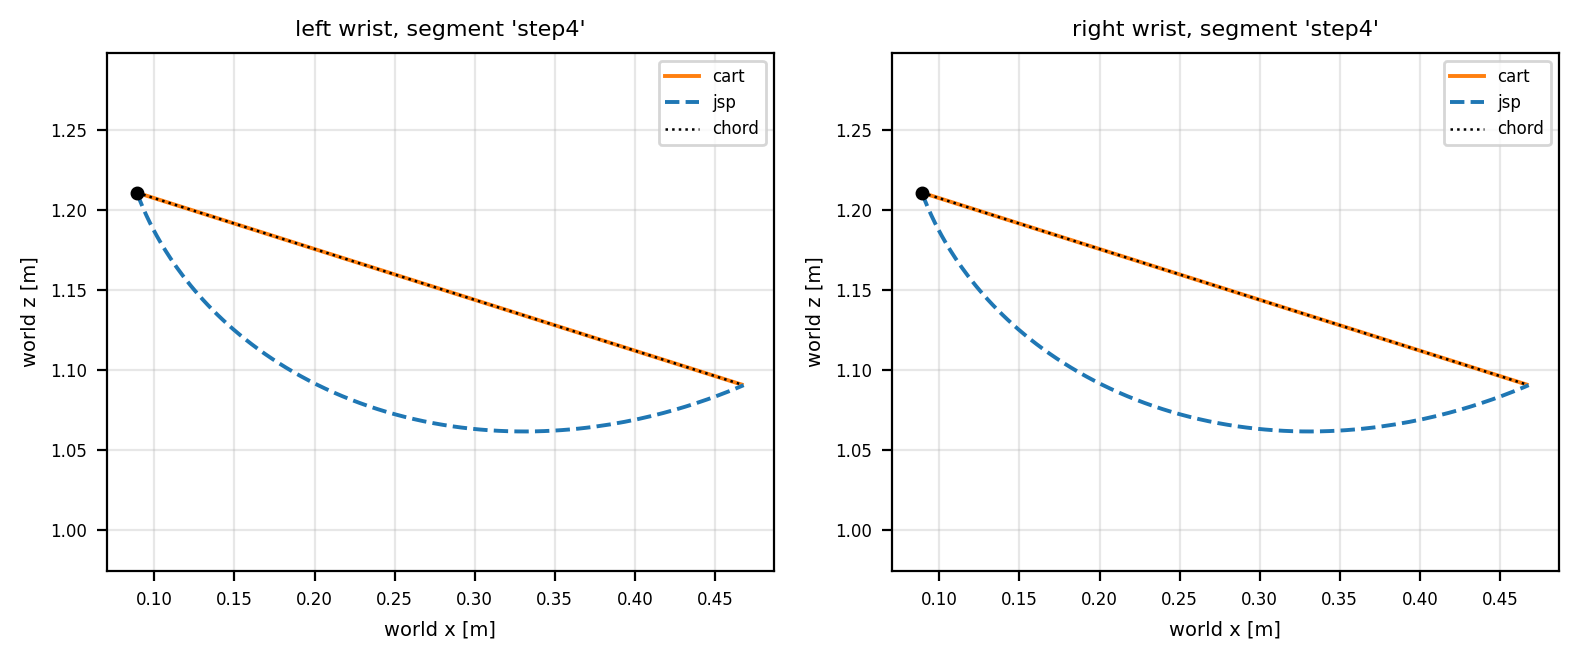


collision sweep (SELF ONLY, no table in the model), margin 0.050 m
   segment  route  samples  min dist [m]  at t [s]  pair                                     level
----------------------------------------------------------------------------------------------------
     start   cart       51        0.0749      0.50  geom[12] <-> geom[46]                    SAFE
              jsp       51        0.0749      0.50  geom[12] <-> geom[46]                    SAFE
     step1   cart      120        0.0742      1.97  geom[12] <-> geom[46]                    SAFE
              jsp      120        0.0741      0.62  geom[12] <-> geom[46]                    SAFE
     step2   cart      120        0.0896      1.67  geom[10] <-> geom[60]                    SAFE
              jsp      120        0.0896      1.04  geom[10] <-> geom[60]                    SAFE
     step3   cart      120        0.0366      3.02  geom[20] <-> geom[30]                    WARNING
              jsp      120        0.0365   

In [8]:
# Offline check -- plan the sequence BOTH ways and put the two side by side

SEQUENCE_NAME = "bring_up"     # "bring_up" or "shut_down"

# joint_speed_limits / joint_acc_limits already carry REAL_SPEED_SCALE (cell 6).
plan_hz            = float(robot_hz)

# joint_speed_limits is per joint; the arm entries are all the revolute ceiling
# and lift_joint is the prismatic one, so read them off the array itself rather
# than from the module constants -- those are UNSCALED.
rev_idx = command_joint_names.index("arm_l_joint1")
pri_idx = command_joint_names.index("lift_joint")
print(f"revolute  v_max {joint_speed_limits[rev_idx]:.4f} rad/s "
      f"({np.rad2deg(joint_speed_limits[rev_idx]):.1f} deg/s) | a_max {joint_acc_limits[rev_idx]:.4f} rad/s^2")
print(f"prismatic v_max {joint_speed_limits[pri_idx]:.4f} m/s              | a_max {joint_acc_limits[pri_idx]:.4f} m/s^2")
print(f"wrist     v_max {CART_LIN_SPEED_MAX:.4f} m/s              | {np.rad2deg(CART_ANG_SPEED_MAX):.1f} deg/s")
print(f"every ceiling above already carries REAL_SPEED_SCALE = {REAL_SPEED_SCALE:.2f}")
print(f"(acceleration is provisional: v_max / {SG2_JOINT_ACC_RAMP_SEC:.2f}s -- verify against the motor specs)\n")

# ---------------------------------------------------------------------------
# 1) Expand the waypoints by joint name and check them against the joint limits
# ---------------------------------------------------------------------------
step_names = SG2_MOTION_SEQUENCES[SEQUENCE_NAME]
# bring_up and shut_down read from different waypoint tables now, so pick by name.
waypoint_table = SG2_SHUTDOWN_WAYPOINTS if SEQUENCE_NAME == "shut_down" else SG2_BRINGUP_WAYPOINTS
waypoints  = [(name, expand_sg2_qpos(command_joint_names, waypoint_table[name]))
              for name in step_names]

all_ok = True
for name, q in waypoints:
    limit_info = check_sg2_joint_limits(env, command_joint_names, q)
    all_ok = all_ok and limit_info["ok"]
    nonzero = [f"{n}={v:+.4f}" for n, v in zip(command_joint_names, q) if abs(v) > 1e-9]
    print(f"[{name:>5s}] joint limits {'OK' if limit_info['ok'] else 'VIOLATED'} | {', '.join(nonzero)}")
    if not limit_info["ok"]:
        print(format_sg2_joint_limit_violations(limit_info))

# ---------------------------------------------------------------------------
# 2) Plan each segment in Cartesian space, with the joint-space plan alongside
# ---------------------------------------------------------------------------
# Both planners are seeded from the same pose at every segment, so the only
# difference between the two columns is the route.
#
# Read `gap` first. It is how far the pose the IK landed on at u=1 is from the
# stored waypoint, and it is not an error -- a 7-DoF arm has a null space, so
# "put the wrist here" does not name a single joint pose. A large gap means this
# segment's goal was never really a Cartesian instruction.
q_seg    = env.get_qpos(joint_names=command_joint_names)
segments = []
print(f"\nplanning {SEQUENCE_NAME}: current pose -> {' -> '.join(step_names)}")
print(f"{'segment':>10s} {'T cart':>7s} {'T jsp':>7s} {'x':>6s} {'D_lin':>7s} {'D_ang':>7s} "
      f"{'ik err':>8s} {'gap':>9s} {'v/v_max':>8s} {'a/a_max':>8s}  route")
print("-" * 104)

total_cart = total_jsp = 0.0
for name, q_goal in waypoints:
    traj = plan_cartesian_wrist(
        env = env, joint_names = command_joint_names,
        q_start = q_seg, q_goal = q_goal, ik_solvers = ik_solvers,
        v_max = joint_speed_limits, a_max = joint_acc_limits,
        hz = plan_hz, min_duration = 0.5, n_knot = CART_N_KNOT,)
    traj_jsp = plan_min_jerk(
        q_start = q_seg, q_goal = q_goal,
        v_max = joint_speed_limits, a_max = joint_acc_limits,
        hz = plan_hz, min_duration = 0.5,)

    # Differentiate the qpos array itself -- that array is all the loop consumes.
    # For this planner it is also the only check that matters: the qpos come out
    # of an IK solve, not out of a formula, so "within the limits" has to be
    # measured rather than assumed.
    dt_plan = 1.0 / plan_hz
    v_num   = np.diff(traj["qpos"], axis=0) / dt_plan
    a_num   = np.diff(v_num,        axis=0) / dt_plan
    v_ratio = np.abs(v_num) / joint_speed_limits[None, :]
    a_ratio = np.abs(a_num) / joint_acc_limits[None, :]
    flag = ("V!" if v_ratio.max() > 1.0 + 1e-6 else "") + ("A!" if a_ratio.max() > 1.0 + 1e-6 else "")
    all_ok = all_ok and v_ratio.max() <= 1.0 + 1e-6 and a_ratio.max() <= 1.0 + 1e-6

    # `param` is which path parameterization won the retime -- see the planner cell.
    route = f"cartesian:{traj['param']}" if traj["cartesian"] else f"joint-space ({traj['reason']})"
    print(f"{name:>10s} {traj['duration']:7.2f} {traj_jsp['duration']:7.2f} "
          f"{traj['duration'] / max(traj_jsp['duration'], 1e-9):5.2f}x "
          f"{traj['D_lin']:7.3f} {np.rad2deg(traj['D_ang']):6.1f}d "
          f"{traj['ik_err_max']:8.4f} {np.rad2deg(traj['endpoint_gap']):8.1f}d "
          f"{v_ratio.max():8.4f} {a_ratio.max():8.4f}  {route} {flag}")

    segments.append({"name": name, "traj": traj, "traj_jsp": traj_jsp})
    total_cart += traj["duration"]
    total_jsp  += traj_jsp["duration"]
    q_seg = q_goal

print("-" * 104)
print(f"{'total':>10s} {total_cart:7.2f} {total_jsp:7.2f} "
      f"{total_cart / max(total_jsp, 1e-9):5.2f}x")
print("ik err [m] = worst residual of the wrist coordinate targets over the knots.")
print("gap        = |IK pose at u=1 - stored waypoint|, the null-space drift this route accepts.")

# ---------------------------------------------------------------------------
# 3) What the two routes do to the wrist -- the whole point of this notebook
# ---------------------------------------------------------------------------
# Both plans end at the same wrist pose. What differs is the route: the Cartesian
# plan's bulge away from the straight line should be at the millimetre level (it
# is only the knot spacing and the IK residual), while the joint-space plan's
# bulge grows as the SQUARE of the joint displacement.
print(f"\nwrist route (max bulge away from the straight line between the endpoints)")
print(f"{'segment':>10s} {'hand':>6s} {'chord [m]':>10s} {'cart [mm]':>10s} {'jsp [mm]':>9s} {'jsp/chord':>10s}")
print("-" * 62)
for segment in segments:
    for label, key in (("cart", "traj"), ("jsp", "traj_jsp")):
        _, segment[f"path_{label}"] = wrist_path_from_qpos(
            env, command_joint_names, segment[key]["qpos"], n_max=200)
    for hand_type in SG2_HAND_TYPES:
        bulge_cart, chord = path_straightness(segment["path_cart"][hand_type])
        bulge_jsp,  _     = path_straightness(segment["path_jsp"][hand_type])
        if chord < 1e-4:
            continue
        # The Cartesian bulge is at the resolution of the knot spacing, so a
        # ratio against it is dividing by noise. Report both in millimetres and
        # scale the joint-space one by the chord instead -- that ratio is the
        # quantity that actually grows with the size of the move.
        print(f"{segment['name']:>10s} {hand_type:>6s} {chord:10.3f} {1e3 * bulge_cart:10.2f} "
              f"{1e3 * bulge_jsp:9.1f} {100.0 * bulge_jsp / chord:9.1f}%")
print("cart [mm] is the knot spacing and the IK residual, nothing else; jsp [mm] is the route.")

# The same thing as a picture, for the segment with the longest wrist travel.
worst_segment = max(
    segments,
    key=lambda seg: max(path_straightness(seg["path_jsp"][h])[1] for h in SG2_HAND_TYPES))
fig, axes = plt.subplots(1, len(SG2_HAND_TYPES), figsize=(4.0 * len(SG2_HAND_TYPES), 3.4))
for ax, hand_type in zip(np.atleast_1d(axes), SG2_HAND_TYPES):
    for label, style, color in (("cart", "-", "tab:orange"), ("jsp", "--", "tab:blue")):
        P = worst_segment[f"path_{label}"][hand_type]
        ax.plot(P[:, 0], P[:, 2], style, lw=1.4, color=color, label=label)
    P = worst_segment["path_cart"][hand_type]
    ax.plot([P[0, 0], P[-1, 0]], [P[0, 2], P[-1, 2]], ':', lw=0.9, color='k', label="chord")
    ax.plot(P[0, 0], P[0, 2], 'o', ms=4, color='k')
    ax.set_title(f"{hand_type} wrist, segment '{worst_segment['name']}'", fontsize=8)
    ax.set_xlabel("world x [m]", fontsize=7); ax.set_ylabel("world z [m]", fontsize=7)
    ax.set_aspect('equal', adjustable='datalim'); ax.grid(alpha=0.3); ax.legend(fontsize=6)
plt.tight_layout(); plt.show()

# ---------------------------------------------------------------------------
# 4) Sweep the planned path for collisions (SELF ONLY -- no table in this scene)
# ---------------------------------------------------------------------------
# A straight Cartesian line is not automatically a safe one -- it is only a
# predictable one. Lifting straight up out of the table is exactly what this
# route is for; sliding straight through the torso on a fold-in leg is exactly
# what it is not.
# The real scene is floor + robot: the table the robot stands at is NOT in the
# model, so a SAFE verdict here says nothing about it. Clear the workspace.
n_sweep_sample = 120
safe_margin    = 0.05

def geom_label(geom_idx):
    return env.geom_names[geom_idx] or f"geom[{geom_idx}]"

q_backup = env.get_qpos(joint_names=command_joint_names)
print(f"\ncollision sweep (SELF ONLY, no table in the model), margin {safe_margin:.3f} m")
print(f"{'segment':>10s} {'route':>6s} {'samples':>8s} {'min dist [m]':>13s} {'at t [s]':>9s}  {'pair':<40s} level")
print("-" * 100)
try:
    for segment in segments:
        for label, key in (("cart", "traj"), ("jsp", "traj_jsp")):
            traj   = segment[key]
            n_step = traj["qpos"].shape[0]
            idxs   = np.unique(np.linspace(0, n_step - 1, min(n_sweep_sample, n_step)).astype(int))
            worst  = None
            for step_idx in idxs:
                env.forward(q=traj["qpos"][step_idx], joint_names=command_joint_names)
                status = get_sg2_self_collision_status(
                    env                  = env,
                    collision_geom_pairs = collision_geom_pairs,
                    native_backend       = native_backend,
                    safe_margin          = safe_margin,
                    signed_distance_topk = 1,)
                if worst is None or status["min_signed_dist"] < worst["min_signed_dist"]:
                    worst = dict(status, t=float(traj["times"][step_idx]))
            info = worst["signed_distance_infos"][0] if worst["signed_distance_infos"] else None
            pair = ("%s <-> %s" % (geom_label(int(info["geom1_idx"])),
                                   geom_label(int(info["geom2_idx"])))) if info else "-"
            if label == "cart":
                all_ok = all_ok and worst["level"] != "collision"
            print(f"{segment['name'] if label == 'cart' else '':>10s} {label:>6s} {len(idxs):8d} "
                  f"{worst['min_signed_dist']:13.4f} {worst['t']:9.2f}  {pair:<40s} {worst['level'].upper()}")
finally:
    env.forward(q=q_backup, joint_names=command_joint_names)
print("-" * 100)
print("negative distance = the planned path goes through something; WARNING = within the margin.")
print("the `jsp` rows are the joint-space planner on the same segment, for comparison only.")

print(f"\nverdict: {'OK' if all_ok else 'FAILED -- see the flagged rows above'}")

**셀 9. 뷰어, 기즈모, 명령 위젯, executor, ZMQ 퍼블리셔 초기화**

루프 주기를 정의한다. `robot_hz = 100`은 퍼블리시 주기이자 **executor의 틱 주기**다 — 계획된 샘플 하나가 발행된 메시지 하나에 1:1로 대응한다.

뷰어를 열고 좌/우 손목에 드래그 가능한 `InteractiveMarker` 기즈모를 실제 로봇의 현재 손목 자세에 맞춰 생성한다. 명령 위젯은 `SG2_MOTION_COMMAND_ROWS`의 표준 행들 위에 **`Robot` OFF/ON 행**을 하나 얹은 것이다. `handle_sg2_motion_command_widget`은 `Motion`/`Preset`/`File`/`Collision`/`EEF`/`Show`만 이름으로 읽고 나머지는 무시하므로 행을 추가해도 문제가 없다.

`SG2CartesianMotionExecutor`는 `speed_limits`/`acc_limits`를 명시적으로 받는다(스케일된 값). 생성 직후 `executor.q_use`를 셀 5에서 로봇으로부터 읽은 자세로 심어 준다 — 그러지 않으면 첫 세그먼트가 MuJoCo의 기본 자세에서 계획된다.

마지막으로 실제 로봇용 퍼블리셔(`pub_robot`)와 렌더용 퍼블리셔(`pub_render`)를 만든다.

In [9]:
env.init_viewer(title="SG2 Cartesian Motion Executor -> Real FFW SG2",
                x_offset=0.24,y_offset=0.00,width=0.76,height=1.0,fontscale=180)
env.viewer.set_cam_info(180.0,2.8,-20.0,[0.0,0.0,0.95])
env.viewer.set_transparency(transparent=True)

markers = {
    hand_type: InteractiveMarker(
        env          = env,
        T            = get_sg2_wrist_control_T(env,hand_type),
        axis_len     = 0.12,
        ring_r       = 0.12,
        control_mode = "pR",)
    for hand_type in hand_types
}

def make_sg2_joint_overlay_text(env, joint_names, mode="rad"):
    """One line per joint group -- hinges in radians, the lift slide in metres.

    sim_joint_controller_sg2_teleop_with_table.ipynb prints the same block off
    its marker controller. There is no controller in this notebook, so the
    groups come straight from SG2_JOINT_MARKER_GROUPS and the values straight
    from MuJoCo. `mode="deg"` switches the hinges to degrees.
    """
    pri_joint_names = set(env.pri_joint_names)
    lines = []
    for group_key, group_joint_names in SG2_JOINT_MARKER_GROUPS.items():
        entries = []
        for joint_name in group_joint_names:
            if joint_name not in joint_names:
                continue
            qpos = float(env.get_qpos(joint_names=[joint_name])[0])
            if joint_name in pri_joint_names:
                entries.append("%.3fm" % qpos)
            else:
                entries.append("%.3f" % (qpos if mode == "rad" else np.rad2deg(qpos)))
        if entries:
            lines.append("%-6s: %s" % (group_key, " ".join(entries)))
    return "\n".join(lines)


# The standard motion rows plus a Robot OFF/ON gate on top.
# handle_sg2_motion_command_widget reads Motion / Preset / File / Collision /
# EEF / Show by name and ignores anything else, so the extra row costs nothing.
ctrl_radio = MultiRadioQtWidget(
    title          = "SG2 Motion Command -> Real",
    x_offset       = 0.00,
    y_offset       = 0.00,
    window_width   = 0.24,
    window_height  = 0.40,
    label_texts    = ["Robot"] + list(SG2_MOTION_COMMAND_ROWS),
    option_texts   = [["OFF","ON"]] + list(SG2_MOTION_COMMAND_ROWS.values()),
    initial_texts  = ["OFF","idle","idle","idle","on","on","all"],)

gripper_slider = MultiSliderQtWidget(
    title          = "SG2 Gripper",
    x_offset       = 0.00,
    y_offset       = 0.42,
    window_width   = 0.24,
    window_height  = 0.14,
    label_texts    = gripper_driver_joint_names,
    slider_mins    = env.get_joint_mins(gripper_driver_joint_names),
    slider_maxs    = env.get_joint_maxs(gripper_driver_joint_names),
    slider_vals    = [gripper_q_by_hand[hand_type] for hand_type in hand_types],
    resolutions    = [0.01]*len(hand_types),)

executor = SG2CartesianMotionExecutor(
    env                = env,
    joint_names        = command_joint_names,
    hz                 = robot_hz,
    min_duration       = 0.5,
    speed_limits       = joint_speed_limits,
    acc_limits         = joint_acc_limits,
    ik_solvers         = ik_solvers,
    cartesian_segments = CARTESIAN_SEGMENTS,
    n_knot             = CART_N_KNOT,)
executor.q_use = q_use.copy()      # seeded from the real robot, not from MuJoCo's default

pub_robot  = ZMQPubSub(role="pub",port=PUB_TO_SG2_PORT,ip=PUB_TO_SG2_IP,verbose=True)
pub_render = ZMQPubSub(role="pub",port=RENDER_PORT,verbose=True)

print("ZMQ publishers")
print("--------------")
print("Robot        : tcp://*:%d"%PUB_TO_SG2_PORT)
print("Renderer pub : tcp://*:%d"%RENDER_PORT)
print("Render view  : run real_render_MetaQuest3_sg2.ipynb in another kernel/window")
print()
print("executor joints (%d): %s"%(len(executor.joint_names),executor.joint_names))
print("planner        : plan_cartesian_wrist, %d knots per segment per arm"%CART_N_KNOT)
print("cartesian segs : %s"%("ALL" if CARTESIAN_SEGMENTS is None else sorted(CARTESIAN_SEGMENTS)))
print("speed scale    : %.2f  (rev %.1f deg/s, wrist %.3f m/s)"%(
    REAL_SPEED_SCALE,np.rad2deg(SG2_MAX_REV_JOINT_SPEED)*REAL_SPEED_SCALE,CART_LIN_SPEED_MAX))
print("motion commands: %s"%list(SG2_MOTION_SEQUENCES))
for name,steps in SG2_MOTION_SEQUENCES.items():
    print("  %10s: %s"%(name," -> ".join(steps)))
print()
print("Robot starts OFF. Turn it ON only after the gizmos sit on the wrists and")
print("the offline check above passed. Switching ON re-reads the robot state and")
print("cancels anything that was running.")

[ZMQ Publisher] pid:[33550] endpoint:[tcp://0.0.0.0:5561]
[ZMQ] role:[pub] ip:[192.168.6.100] port:[5561] hwm:[1] conflate:[True]
[ZMQ Publisher] pid:[33550] endpoint:[tcp://0.0.0.0:5556]
[ZMQ] role:[pub] ip:[192.168.6.100] port:[5556] hwm:[1] conflate:[True]
ZMQ publishers
--------------
Robot        : tcp://*:5561
Renderer pub : tcp://*:5556
Render view  : run real_render_MetaQuest3_sg2.ipynb in another kernel/window

executor joints (19): ['lift_joint', 'head_joint1', 'head_joint2', 'arm_l_joint1', 'arm_l_joint2', 'arm_l_joint3', 'arm_l_joint4', 'arm_l_joint5', 'arm_l_joint6', 'arm_l_joint7', 'arm_r_joint1', 'arm_r_joint2', 'arm_r_joint3', 'arm_r_joint4', 'arm_r_joint5', 'arm_r_joint6', 'arm_r_joint7', 'gripper_l_joint1', 'gripper_r_joint1']
planner        : plan_cartesian_wrist, 30 knots per segment per arm
cartesian segs : ['wrist_lift']
speed scale    : 1.00  (rev 60.0 deg/s, wrist 0.150 m/s)
motion commands: ['bring_up', 'bring_up_origin', 'shut_down']
    bring_up: start -> ste

**셀 10. 메인 루프 — OFF/ON 게이트 → executor 틱 → 로봇 퍼블리시 → 기즈모/렌더링**

타이머 세 개가 한 루프 안에서 돈다. 매 pass의 처리 순서:

1. **`Robot` OFF/ON 게이트** — 하드웨어를 다치게 할 수 있는 유일한 전이라서 pass의 맨 앞에서 처리한다. OFF→ON이면 돌고 있던 모션을 취소하고, `get_latest_robot_qpos`로 실제 상태를 다시 읽고, 오차가 `MAX_ON_DRIFT_RAD`를 넘으면 **ON을 거부하고 스위치를 OFF로 되돌린다**. 통과하면 `env`, `executor.q_use`, 기즈모를 모두 그 자세에서 다시 심는다.
2. **명령 위젯 읽기** — 루프 pass당 정확히 한 번. `is_toggled`가 이벤트를 소비하므로 같은 pass에서 두 번 부르면 놓친다.
3. **`robot_hz` 틱** — executor가 active면 `tick()`을 한 번 돌린다. 출력단은 `env.forward(q_cmd) → apply_sg2_joint_rate_limit → np.clip → env.forward`로, 다른 real 노트북이 손으로 쓰는 순서와 같다. 그런 다음 `Robot`이 ON이면 그 결과를 퍼블리시한다. **executor는 시계가 아니라 인덱스로 진행하므로**, 루프가 느려지면 모션이 길어질 뿐 앞으로 건너뛰지 않는다.
4. **`input_hz` 틱** — executor가 idle일 때만 기즈모 IK를 푼다. active면 기즈모를 손목 위로 다시 얹기만 한다(둘이 같은 관절을 같은 틱에 쓰면 안 된다). idle 경로에도 **`apply_sg2_joint_rate_limit`을 적용한다** — `real_eef_controller_sg2_teleop.ipynb`에는 이게 없고, 사람이 기즈모를 천천히 끄는 덕분에 안전할 뿐이며 그것을 강제하는 장치는 없다.
5. **`render_hz` 틱** — 충돌 검사(토글 시), 그리기, 오버레이, 그리고 `send_render_qpos`로 렌더러 노트북에 동일 정보를 전송한다. 모션이 도는 동안의 최근접 거리는 `coll_log`에 함께 기록되어 마지막 분석 셀에서 쓰인다.

종료 시(예외/Ctrl-C 포함) executor를 취소하고 퍼블리셔와 위젯을 정리한 뒤 뷰어를 닫는다.

In [10]:
# Main loop -- gizmo IK when idle, planned Cartesian playback when a command runs,
# and one published message per executor tick.

collision_margin = 0.05        # shared by the live check and the analysis cell

tmr_input  = SimpleTimer(name="Marker IK", Hz=input_hz,  verbose=False)
tmr_robot  = SimpleTimer(name="Robot Pub", Hz=robot_hz,  verbose=False)
tmr_render = SimpleTimer(name="Render Pub",Hz=render_hz, verbose=True)
tmr_input.start(); tmr_robot.start(); tmr_render.start()
env.reset_wall_time(); env.reset_sim_time()

# Log of the most recent executed motion, consumed by the analysis cell below.
exec_log = {"t": [], "q_cmd": [], "q_use": [], "limited": [], "clipped": [],
            "dq_ratio": [], "dt": [], "segment": []}
exec_log_label = ""
# Every motion before the current one, so a session that ran shut_down and then
# bring_up_origin can be charted as two motions instead of only the last. Kept
# small on purpose: only what section 4e replays through inverse dynamics.
exec_log_history     = []
EXEC_LOG_HISTORY_MAX = 8
coll_log = {"t": [], "min_dist": [], "level": [], "pair": [], "segment": []}

collision_status     = None
last_command_message = ""
robot_pub_hz_actual  = 0.0
prev_on_flag         = False
was_active           = False
# The sliders and the executor both drive the grippers, so the loop has to know
# which of them moved last. Without this the idle branch writes the slider value
# on every input tick and silently undoes grip_close / shut_down's gripper_open.
gripper_slider_prev  = np.asarray(gripper_slider.get_values(),dtype=np.float64)
t_motion             = 0.0
wrist_targets_by_hand = {hand_type:marker.get_T(update=False,draw=False)
                         for hand_type,marker in markers.items()}

print("running. drag the wrist gizmos, then pick Motion -> bring_up / shut_down.")
print("Robot is OFF: nothing reaches the robot until you switch it ON.")

try:
    while env.is_viewer_alive() and ctrl_radio.isVisible():
        app.processEvents()

        # ------------------------------------------------------------------
        # Robot OFF/ON gate. This is the one transition that can hurt the
        # hardware, so it is handled before anything else in the pass.
        # ------------------------------------------------------------------
        on_flag = ctrl_radio.get_button_option(label_text="Robot") == "ON"
        if on_flag and not prev_on_flag:
            # The sim has been running open-loop while the robot was OFF, so it
            # may sit anywhere. Whatever gap exists right now is exactly the step
            # the robot would be commanded to take on the first message. Re-read
            # the real state, refuse if the gap is large, and re-seed everything
            # from it -- the executor included, or its next segment would be
            # planned from a pose the robot is not in.
            if executor.cancel():
                print("[Robot] ON: cancelled the motion that was running.")
            try:
                q_real,recv_count = get_latest_robot_qpos(
                    env             = env,
                    q_msg_layout    = q_msg_layout,
                    use_joint_names = command_joint_names,
                    sub_ip          = SUB_FROM_SG2_IP,
                    sub_port        = SUB_FROM_SG2_PORT,
                    timeout_sec     = 1.0,
                    verbose         = False,)
                drift = float(np.max(np.abs(
                    q_real - env.get_qpos(joint_names=command_joint_names))))
                if drift > MAX_ON_DRIFT_RAD:
                    raise ValueError(
                        "sim is %.1f deg away from the robot (limit %.1f deg)"
                        %(np.rad2deg(drift),np.rad2deg(MAX_ON_DRIFT_RAD)))
                q_use = np.clip(q_real,q_use_min,q_use_max)
                env.forward(q=q_use,joint_names=command_joint_names)
                executor.q_use = q_use.copy()
                for hand_type,marker in markers.items():
                    marker.set_T(get_sg2_wrist_control_T(env,hand_type),update_T0=True)
                last_command_message = "robot ON: resynced (drift %.2f deg)"%np.rad2deg(drift)
                print("[Robot] ON. %s"%last_command_message)
            except Exception as err:
                ctrl_radio.set_button_option(label_text="Robot",option_text="OFF")
                on_flag = False
                last_command_message = "robot ON REFUSED: %s"%err
                print("[Robot] %s"%last_command_message)
        elif (not on_flag) and prev_on_flag:
            print("[Robot] OFF.")
        prev_on_flag = on_flag

        # Read the widget once per loop pass, outside the timers, so a command
        # reacts on the pass it is clicked. (is_toggled consumes the event.)
        command_info = handle_sg2_motion_command_widget(
            widget=ctrl_radio, executor=executor, ik_solvers=ik_solvers)
        if command_info["message"]:
            last_command_message = command_info["message"]
            print("[Command] %s"%last_command_message)
        if command_info["sync_requested"]:
            for hand_type,marker in markers.items():
                marker.set_T(get_sg2_wrist_control_T(env,hand_type),update_T0=True)

        # A newly started motion gets a fresh log. The label is compared as well
        # as the idle flag: a command pressed while another one is still running
        # restarts the executor without it ever going idle, and without this the
        # second motion would be logged onto the tail of the first under the
        # first one's name.
        if executor.is_active and (not was_active or executor.label != exec_log_label):
            if len(exec_log["t"]) >= 3:
                exec_log_history.append({
                    "label"  : exec_log_label,
                    "t"      : np.array(exec_log["t"],dtype=np.float64),
                    "q_use"  : np.array(exec_log["q_use"],dtype=np.float64),
                    "segment": list(exec_log["segment"]),})
                del exec_log_history[:-EXEC_LOG_HISTORY_MAX]
            exec_log = {key: [] for key in exec_log}
            coll_log = {key: [] for key in coll_log}
            exec_log_label = executor.label
            t_motion = 0.0
        # A motion that just finished may have moved the grippers. Push what it
        # reached back into the sliders, or the idle branch below would treat the
        # stale slider position as the user's intent and reopen the hand.
        if was_active and not executor.is_active:
            reached = [float(env.get_qpos(joint_names=[SG2_GRIPPER_DRIVER_JOINT_NAMES[hand_type]])[0])
                       for hand_type in hand_types]
            gripper_slider.set_values(reached)
            gripper_slider_prev = np.asarray(reached,dtype=np.float64)
            for hand_type,value in zip(hand_types,reached):
                gripper_q_by_hand[hand_type] = value
        was_active = executor.is_active

        # ------------------------------------------------------------------
        # robot_hz: one executor tick, then one published message
        # ------------------------------------------------------------------
        # The executor owns the output stage on these ticks:
        #     env.forward(q_cmd) -> apply_sg2_joint_rate_limit -> np.clip -> env.forward
        # which is the same order the other real notebooks write by hand. Ticking
        # here rather than on a separate timer means every planned sample is
        # published exactly once: the executor advances by index, not by clock, so
        # a slow pass makes the motion take longer, never makes it jump.
        if tmr_robot.do_run():
            if executor.is_active:
                info = executor.tick(dt=getattr(tmr_robot,"sec_elps_diff",None))
                if info is not None:
                    q_use = np.asarray(info["q_use"],dtype=np.float64)
                    t_motion += info["dt"]
                    exec_log["t"       ].append(t_motion)
                    exec_log["q_cmd"   ].append(np.array(info["q_cmd"],dtype=np.float64))
                    exec_log["q_use"   ].append(q_use.copy())
                    exec_log["limited" ].append(info["limited"])
                    exec_log["clipped" ].append(info["clipped"])
                    exec_log["dq_ratio"].append(info["max_dq_ratio"])
                    exec_log["dt"      ].append(info["dt"])
                    exec_log["segment" ].append(info["segment"])
                    if info["done"]:
                        last_command_message = (
                            "%s: done in %.2fs (%d ticks, %d rate limited, %d clipped)"
                            %(exec_log_label,t_motion,len(exec_log["t"]),
                              int(np.sum(exec_log["limited"])),int(np.sum(exec_log["clipped"]))))
                        print("[Command] %s"%last_command_message)
            if on_flag:
                robot_pub_hz_actual = 1.0/tmr_robot.sec_elps_diff if tmr_robot.sec_elps_diff > 0 else 0.0
                pub_robot.send(obj=get_qmsg_from_qpos(qpos=q_use,q_msg_layout=q_msg_layout))
            else:
                robot_pub_hz_actual = 0.0
            tmr_robot.end()

        # ------------------------------------------------------------------
        # input_hz: gizmo IK, but only while the executor is idle
        # ------------------------------------------------------------------
        # The gizmo IK and the executor must never write the same joints on the
        # same tick, so exactly one of them owns the joints at any moment.
        if tmr_input.do_run():
            if executor.is_active:
                # The executor owns the joints; the gizmos follow the wrists so a
                # gizmo left behind by an earlier drag cannot yank the arm back
                # the moment the motion ends.
                for hand_type,marker in markers.items():
                    marker.set_T(get_sg2_wrist_control_T(env,hand_type),update_T0=True)
            else:
                wrist_targets_by_hand = {
                    hand_type: marker.get_T(update=True,draw=False)
                    for hand_type,marker in markers.items()
                }
                arm_ik_info_by_hand = {hand_type:None for hand_type in hand_types}
                collision_ik_result = solve_sg2_collision_aware_wrist_ik(
                    env                    = env,
                    tracking_solver        = collision_ik_solvers["tracking"],
                    depenetration_solver   = None,
                    wrist_targets_by_hand  = wrist_targets_by_hand,
                    collision_geom_pairs   = collision_geom_pairs,
                    native_backend         = native_backend,
                    safe_margin            = collision_margin,
                    signed_distance_topk   = 5,
                    enable_depenetration   = False,)
                active_ik_solver = collision_ik_result["solver"]
                last_solved_wrist_target,arm_ik_info_by_hand = update_last_solved_wrist_targets(
                    last_solved_wrist_target = last_solved_wrist_target,
                    arm_ik_info_by_hand      = arm_ik_info_by_hand,
                    attached_wrist_targets   = wrist_targets_by_hand,
                    ik_info                  = collision_ik_result["ik_info"],)

                # Only write the grippers when a slider actually moved. Writing
                # unconditionally would fight the executor: the tick that ends a
                # grip_close runs this branch in the same pass, before the resync
                # above has had a chance to run, and would reopen the hand.
                slider_values = np.asarray(gripper_slider.get_values(),dtype=np.float64)
                if np.any(np.abs(slider_values - gripper_slider_prev) > 1e-9):
                    for hand_type,gripper_q in zip(hand_types,slider_values):
                        gripper_q_by_hand[hand_type] = float(gripper_q)
                        set_sg2_gripper_qpos(env,hand_type,gripper_q_by_hand[hand_type])
                    gripper_slider_prev = slider_values

                # real_eef_controller_sg2_teleop.ipynb clips here but does NOT rate
                # limit: it is safe only because a hand drags the gizmo a few mm per
                # tick. Nothing enforces that, and this notebook can hand the same
                # joints to a planner, so the limit is applied on both paths. The
                # ceilings are the executor's own, so the two agree by construction.
                rate_limit_info = apply_sg2_joint_rate_limit(
                    env          = env,
                    joint_names  = command_joint_names,
                    q_prev       = q_use,
                    dt           = getattr(tmr_input,"sec_elps_diff",1.0/input_hz),
                    speed_limits = joint_speed_limits,)
                q_use = np.clip(rate_limit_info["qpos"],q_use_min,q_use_max)
                env.forward(q=q_use,joint_names=command_joint_names)

                # The gizmos just moved the arms, so the executor's notion of the
                # last commanded pose is stale. Refresh it, or the first tick of
                # the next command would be rate-limited against an old pose.
                executor.q_use = q_use.copy()

            T_sg2_wrist = {hand_type:get_sg2_wrist_control_T(env,hand_type)
                           for hand_type in hand_types}
            render_arm_ik_targets = get_solver_target_infos(active_ik_solver,env)
            tmr_input.end()

        # ------------------------------------------------------------------
        # render_hz: draw, overlay, and feed the renderer notebook
        # ------------------------------------------------------------------
        if tmr_render.do_run():
            shown_hand_types = (list(hand_types) if command_info["show_hand"] == "all"
                                else [command_info["show_hand"]])

            collision_status = None
            if command_info["check_collision"]:
                collision_status = get_sg2_self_collision_status(
                    env                  = env,
                    collision_geom_pairs = collision_geom_pairs,
                    native_backend       = native_backend,
                    safe_margin          = collision_margin,
                    signed_distance_topk = 5,)
                draw_sg2_self_collision(env,collision_status)
                if executor.is_active:
                    infos   = collision_status["signed_distance_infos"]
                    closest = min(infos,key=lambda info: info["signed_dist"]) if infos else None
                    coll_log["t"       ].append(t_motion)
                    coll_log["min_dist"].append(collision_status["min_signed_dist"])
                    coll_log["level"   ].append(collision_status["level"])
                    coll_log["segment" ].append(executor.segment_label)
                    coll_log["pair"    ].append(
                        "%s <-> %s"%(closest["body1_name"],closest["body2_name"])
                        if closest is not None else "-")
            if command_info["show_eef"]:
                draw_sg2_wrist_frames(env)

            env.plot_global_coordinate_axes()
            env.plot_links_between_bodies(r=0.001)
            for hand_type in shown_hand_types:
                markers[hand_type].draw()

            env.viewer_text_overlay("Command","robot %s | pub %.1fHz"%(
                "ON" if on_flag else "OFF",robot_pub_hz_actual),loc="top left")
            env.viewer_text_overlay("Executor",executor.status_text(),loc="top left")
            env.viewer_text_overlay("Marker","\n".join(
                "%s: %s"%(hand_labels[hand_type],markers[hand_type].get_status())
                for hand_type in shown_hand_types),loc="top left")
            env.viewer_text_overlay("Joint",
                make_sg2_joint_overlay_text(env,command_joint_names,mode="rad"),loc="top left")
            if command_info["show_eef"]:
                env.viewer_text_overlay("EEF",make_sg2_eef_overlay_text(env),loc="top left")
            env.viewer_text_overlay("Collision",
                make_sg2_self_collision_overlay_text(collision_status),loc="top left")
            env.viewer_text_overlay("Gripper"," | ".join(
                "%s %.2f"%(hand_labels[hand_type],gripper_q_by_hand[hand_type])
                for hand_type in hand_types),loc="top left")
            env.viewer_text_overlay("Last",last_command_message,loc="top left")
            env.render()

            send_render_qpos(
                pub_render          = pub_render,
                qpos                = q_use,
                joint_names         = command_joint_names,
                q_msg_layout        = q_msg_layout,
                msg_type            = "real_motion_executor_cartesian_ffw_sg2",
                on_flag             = on_flag,
                robot_hz            = robot_hz,
                render_hz           = render_hz,
                robot_pub_hz_actual = robot_pub_hz_actual,
                extra               = {
                    "raw_robot_command_on" : on_flag,
                    "attached"             : {hand_type:True for hand_type in hand_types},
                    "attach_phase"         : {hand_type:"marker" for hand_type in hand_types},
                    "attach_progress"      : {hand_type:1.0 for hand_type in hand_types},
                    "quest_ok"             : {hand_type:False for hand_type in hand_types},
                    "quest_all_ok"         : False,
                    "collision_ik_mode"    : collision_ik_result.get("mode","idle"),
                    "min_signed_dist"      : float(collision_ik_result.get("min_signed_dist",np.nan)),
                    "safe_margin"          : float(collision_ik_result.get("safe_margin",collision_margin)),
                    "T_quest_target"       : copy_hand_T_dict(wrist_targets_by_hand),
                    "T_sg2_wrist"          : copy_hand_T_dict(T_sg2_wrist),
                    "active_arm_ik_targets": render_arm_ik_targets,
                    "arm_ik_err_best"      : {
                        hand_type:None
                        if arm_ik_info_by_hand[hand_type] is None
                        else float(arm_ik_info_by_hand[hand_type]["ik_err_best"])
                        for hand_type in hand_types
                    },
                    "gripper_q"            : dict(gripper_q_by_hand),
                    "executor_active"      : bool(executor.is_active),
                    "executor_segment"     : executor.segment_label,
                    "executor_label"       : executor.label,
                },)
            tmr_render.end()

except KeyboardInterrupt:
    print("Interrupted.")
finally:
    executor.cancel()
    pub_render.close()
    pub_robot.close()
    gripper_slider.close()
    ctrl_radio.close()
    if getattr(env,"final_rgb_img",None) is not None:
        imshow(env.final_rgb_img,fig_w=6,title="Final scene",title_fs=8)
    env.close_viewer()
    print("Done.")

[Render Pub] Initialized with [5.0]HZ. MAX_SEC:[inf]sec.
[Render Pub] Start ([5.0]HZ. MAX_SEC:[inf]sec).
running. drag the wrist gizmos, then pick Motion -> bring_up / shut_down.
Robot is OFF: nothing reaches the robot until you switch it ON.
[Render Pub][1] run delayed! T:[200.0]ms run:[211.1]ms]
[Render Pub][86] run delayed! T:[200.0]ms run:[246.1]ms]
[Render Pub][87][17.3s] delayed! T:[200.0]ms interval:[253.5]ms prev_run:[246.1]ms.
[Render Pub][118][23.5s] delayed! T:[200.0]ms interval:[261.6]ms prev_run:[77.5]ms.
[Render Pub][118] run delayed! T:[200.0]ms run:[397.9]ms]
[Render Pub][119][23.9s] delayed! T:[200.0]ms interval:[409.8]ms prev_run:[397.9]ms.
[Render Pub][132] run delayed! T:[200.0]ms run:[216.0]ms]
[Render Pub][133][26.5s] delayed! T:[200.0]ms interval:[239.1]ms prev_run:[216.0]ms.
[Render Pub][151] run delayed! T:[200.0]ms run:[456.8]ms]
[Render Pub][152][30.6s] delayed! T:[200.0]ms interval:[522.8]ms prev_run:[456.8]ms.
[ZMQ Subscriber] pid:[33550] endpoint:[tcp://19

**셀 11. 마지막으로 실행된 모션 분석**

`sim_motion_executor_cartesian_test.ipynb`의 분석 셀과 동일하며, 실기에서는 읽는 목적이 달라진다.

- **위치 / 속도** — 관절별 `q_cmd`(점선)와 `q_use`(실선). **두 선이 겹쳐 보이는 것이 정상**이고, 그것이 `rate limit engaged: 0`과 `joint limit clipped: 0`의 시각적 형태다. 점선이 실선에서 벌어지기 시작하면 5번 항목의 두 카운터 중 어느 쪽이 올라갔는지 확인한다. 원본 joint-space 노트북에서는 계획이 `v_max`로 만든 공식이라 상한 준수가 구조적으로 보장되지만, **여기서는 `qpos`가 IK 해에서 나오므로 상한 준수는 리타이밍 단계의 결과**다. 이 노트북에서 `rate limit engaged`가 0이 아니면 루프가 밀린 것이 아니라 리타이밍이 무언가를 놓친 것이다.
- **손목 높이와 수직 속도** — 로그된 `q_use`를 FK로 재생해 손이 실제로 어디를 지났는지 복원한다. 관절 그래프로는 답할 수 없는 질문이고, `shut_down`이라면 주황색 `wrist_lift` 밴드에서 z가 깔끔한 램프로 오르고 bulge가 mm 수준이어야 한다.
- **세그먼트별 분해** — 어느 구간이 상한에 붙어 달렸고 어느 관절이 페이스를 정했는지.
- **플래너가 내린 결정** — 세그먼트별 route / `D_lin` / `ik err` / **`endpoint_gap`**. 마지막 열이 접힘 구간을 지나며 계속 커진다면 `CARTESIAN_SEGMENTS`를 `{"wrist_lift"}`로 좁히라는 신호다.
- **최근접 거리** — `render_hz`로 샘플링된 자기충돌 최근접 거리. **이 검사는 아무것도 멈추지 않는다.** 씬에 책상이 없으므로 자기충돌만 본다.

실기 운용에서는 여기에 하나가 더 붙는다: `loop timing` 행의 `effective Hz`가 `robot_hz`보다 크게 낮으면 퍼블리시 주기가 그만큼 성긴 것이므로 `render_hz`를 낮춘다. 모션이 위험해지지는 않지만(느려질 뿐) 로봇 쪽 보간에 의존하는 구간이 길어진다.

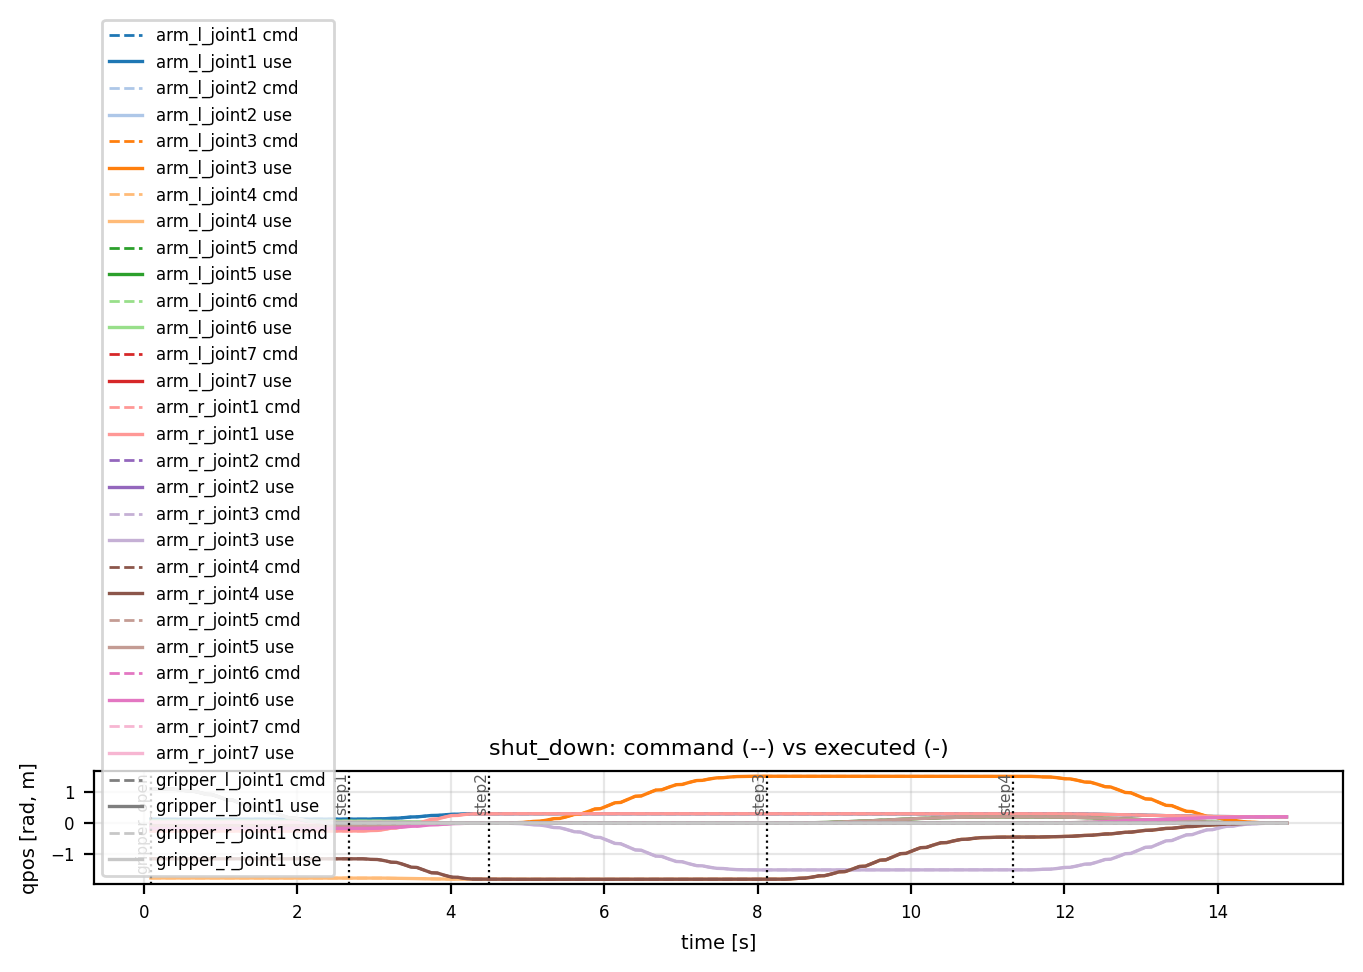

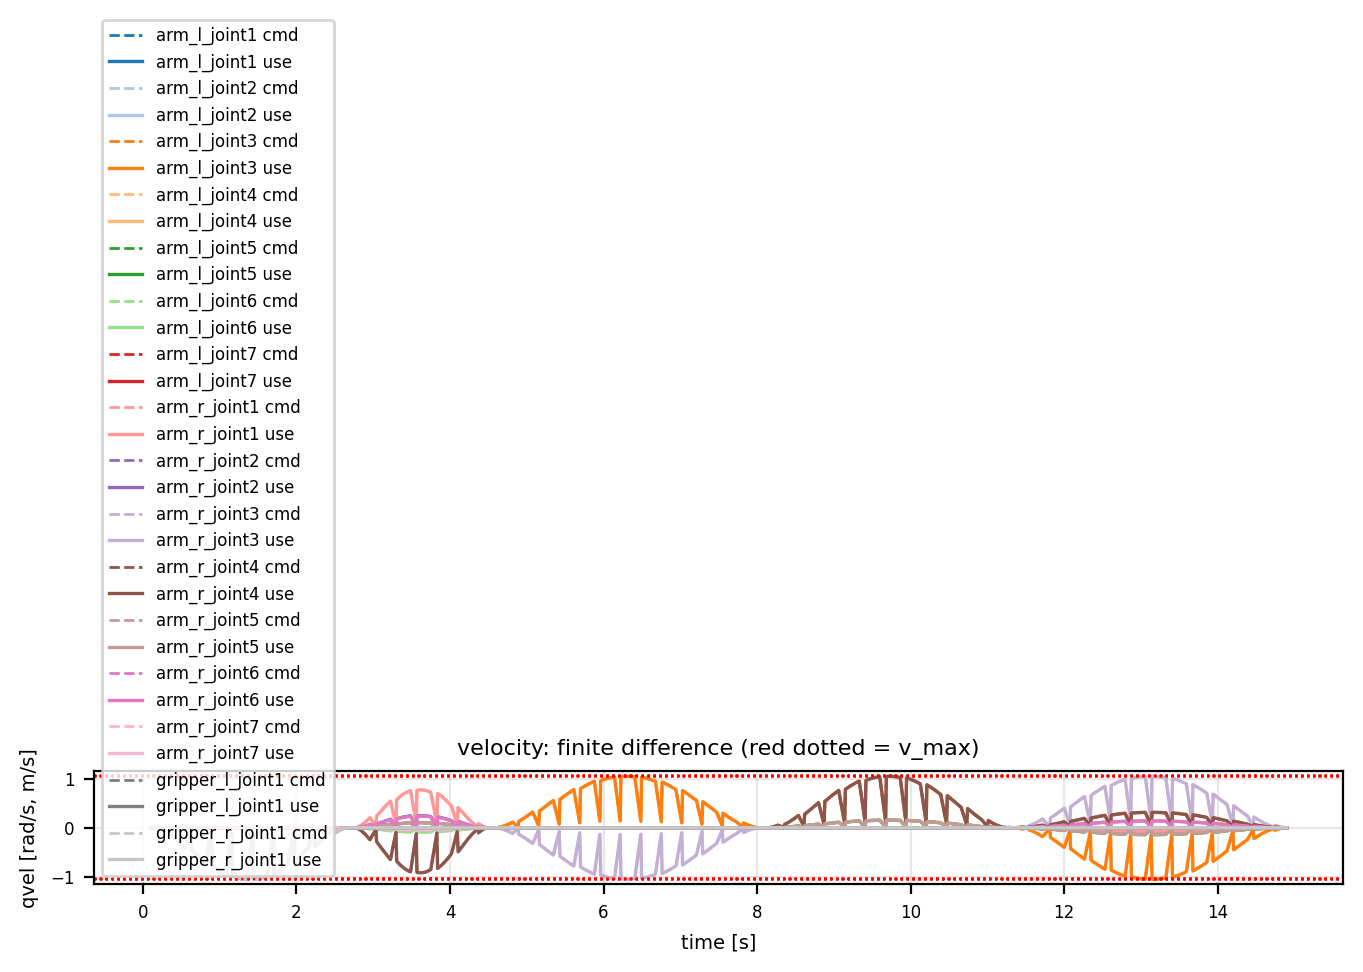

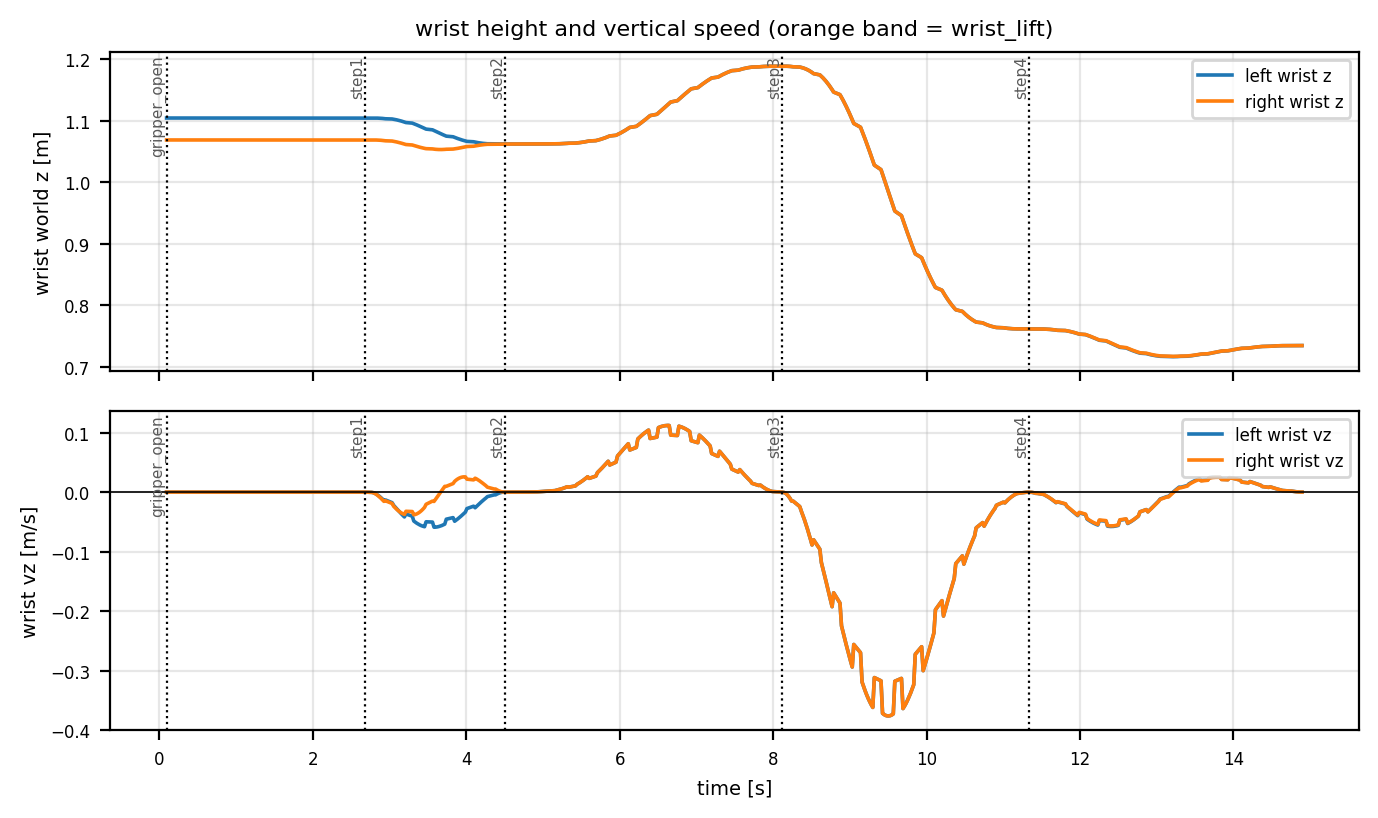

wrist lift          : no wrist_lift segment in this motion -- either it was not a shut_down, or both wrists were already at or above the lift height.

       segment   hand  chord [m]  bulge [mm]  bulge/chord
---------------------------------------------------------
         step1   left      0.073         1.4         1.9%
         step1  right      0.162        13.1         8.1%
         step2   left      0.628       123.6        19.7%
         step2  right      0.628       123.6        19.7%
         step3   left      0.529        92.8        17.5%
         step3  right      0.529        92.8        17.5%
         step4   left      0.190        64.8        34.1%
         step4  right      0.190        62.7        33.0%

       segment  T [s]  ticks  v/v_max  a/a_max     pace-setting joint   its travel
------------------------------------------------------------------------------------
  gripper_open   2.58    198     1.00    43.94       gripper_l_joint1     63.0 deg
         step1   

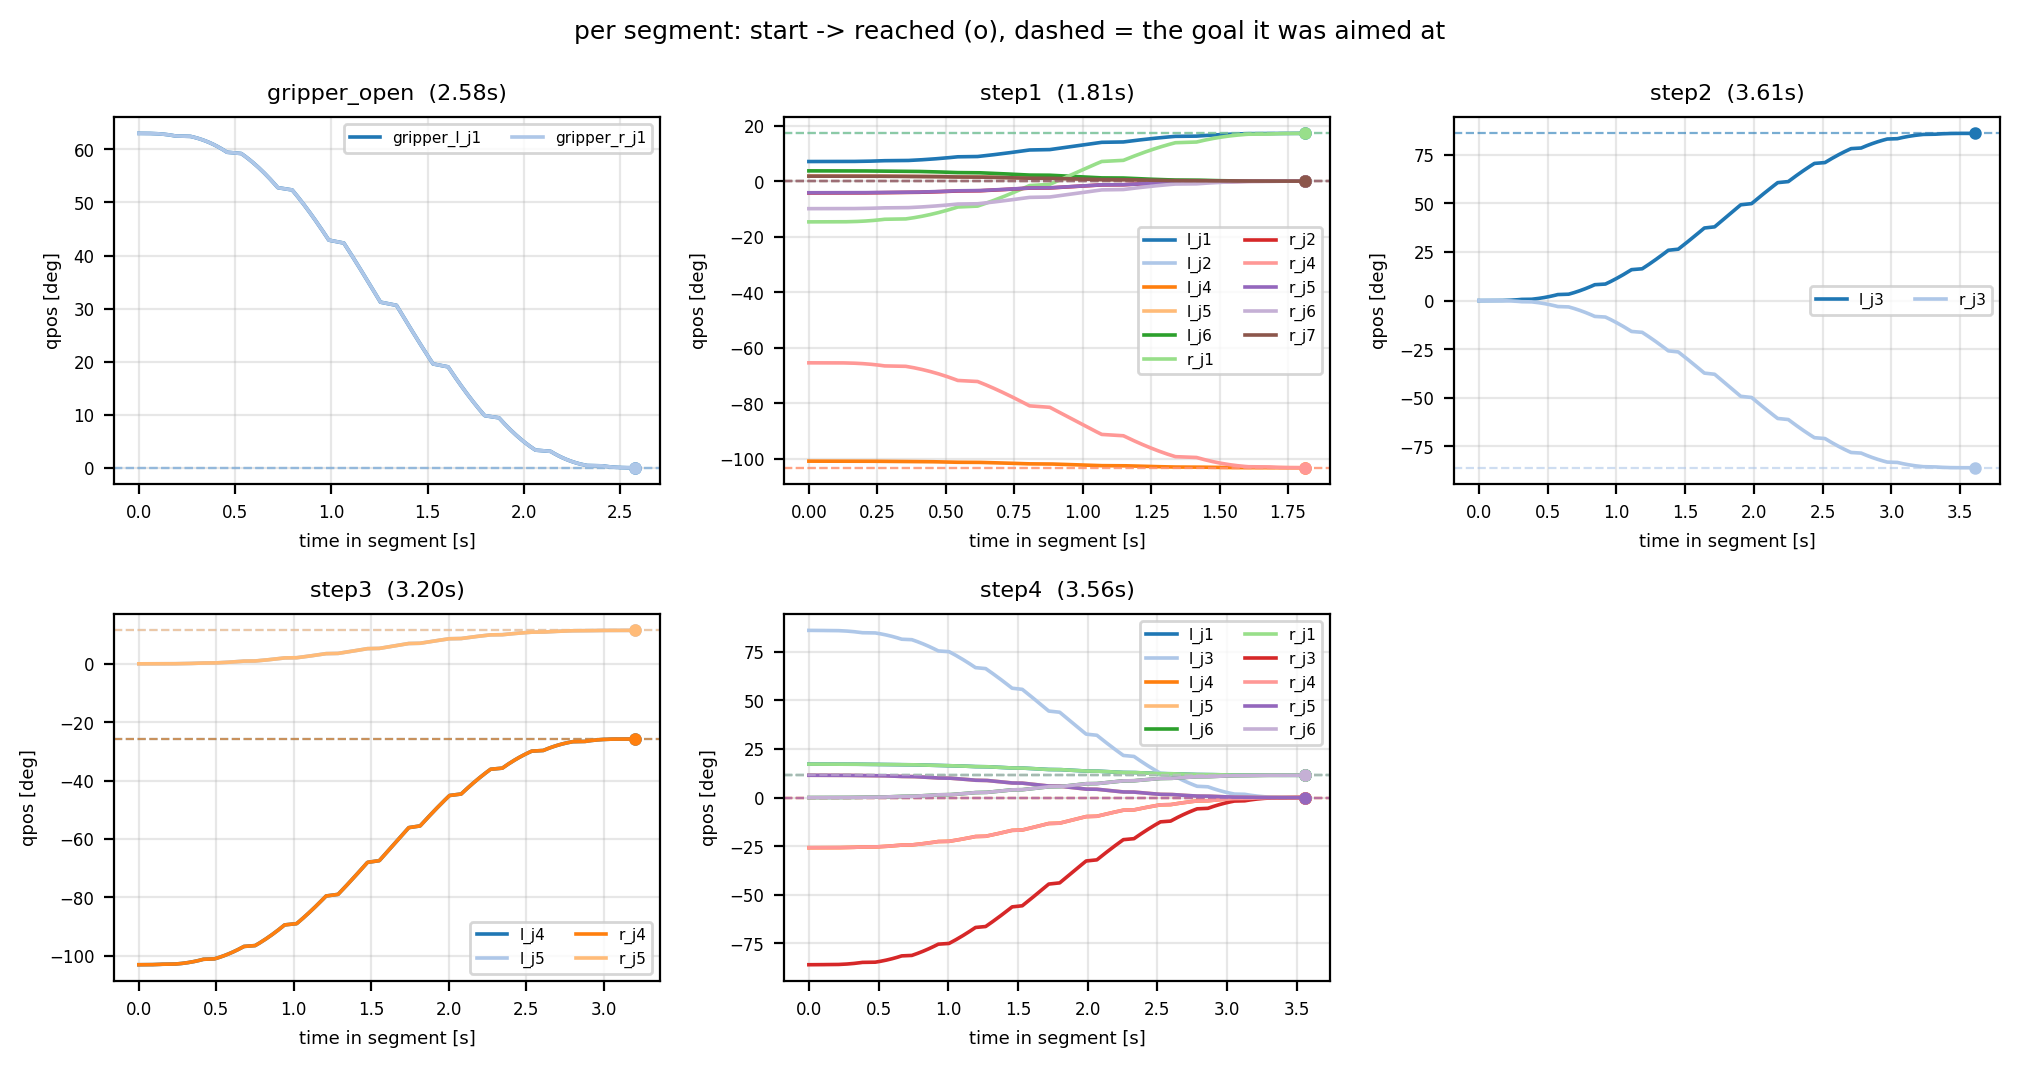


       segment           joint    start  reached     goal   travel  residual
----------------------------------------------------------------------------
  gripper_opengripper_l_joint1     63.0      0.0      0.0     63.0      0.0 deg
         step1    arm_l_joint1      7.1     17.2     17.2     10.1      0.0 deg
         step2    arm_l_joint3      0.0     85.9     85.9     85.9      0.0 deg
         step3    arm_l_joint4   -103.1    -25.8    -25.8     77.3      0.0 deg
         step4    arm_l_joint1     17.2     11.5     11.5      5.7      0.0 deg
----------------------------------------------------------------------------
residual = how far the worst joint of that segment stopped short of the stored
waypoint. Not an error: a 7-DoF arm reaches the wrist pose with a whole family of
joint poses, and this route picks whichever one the IK walked into. Large and
growing across the fold-in legs is the signal to narrow CARTESIAN_SEGMENTS.


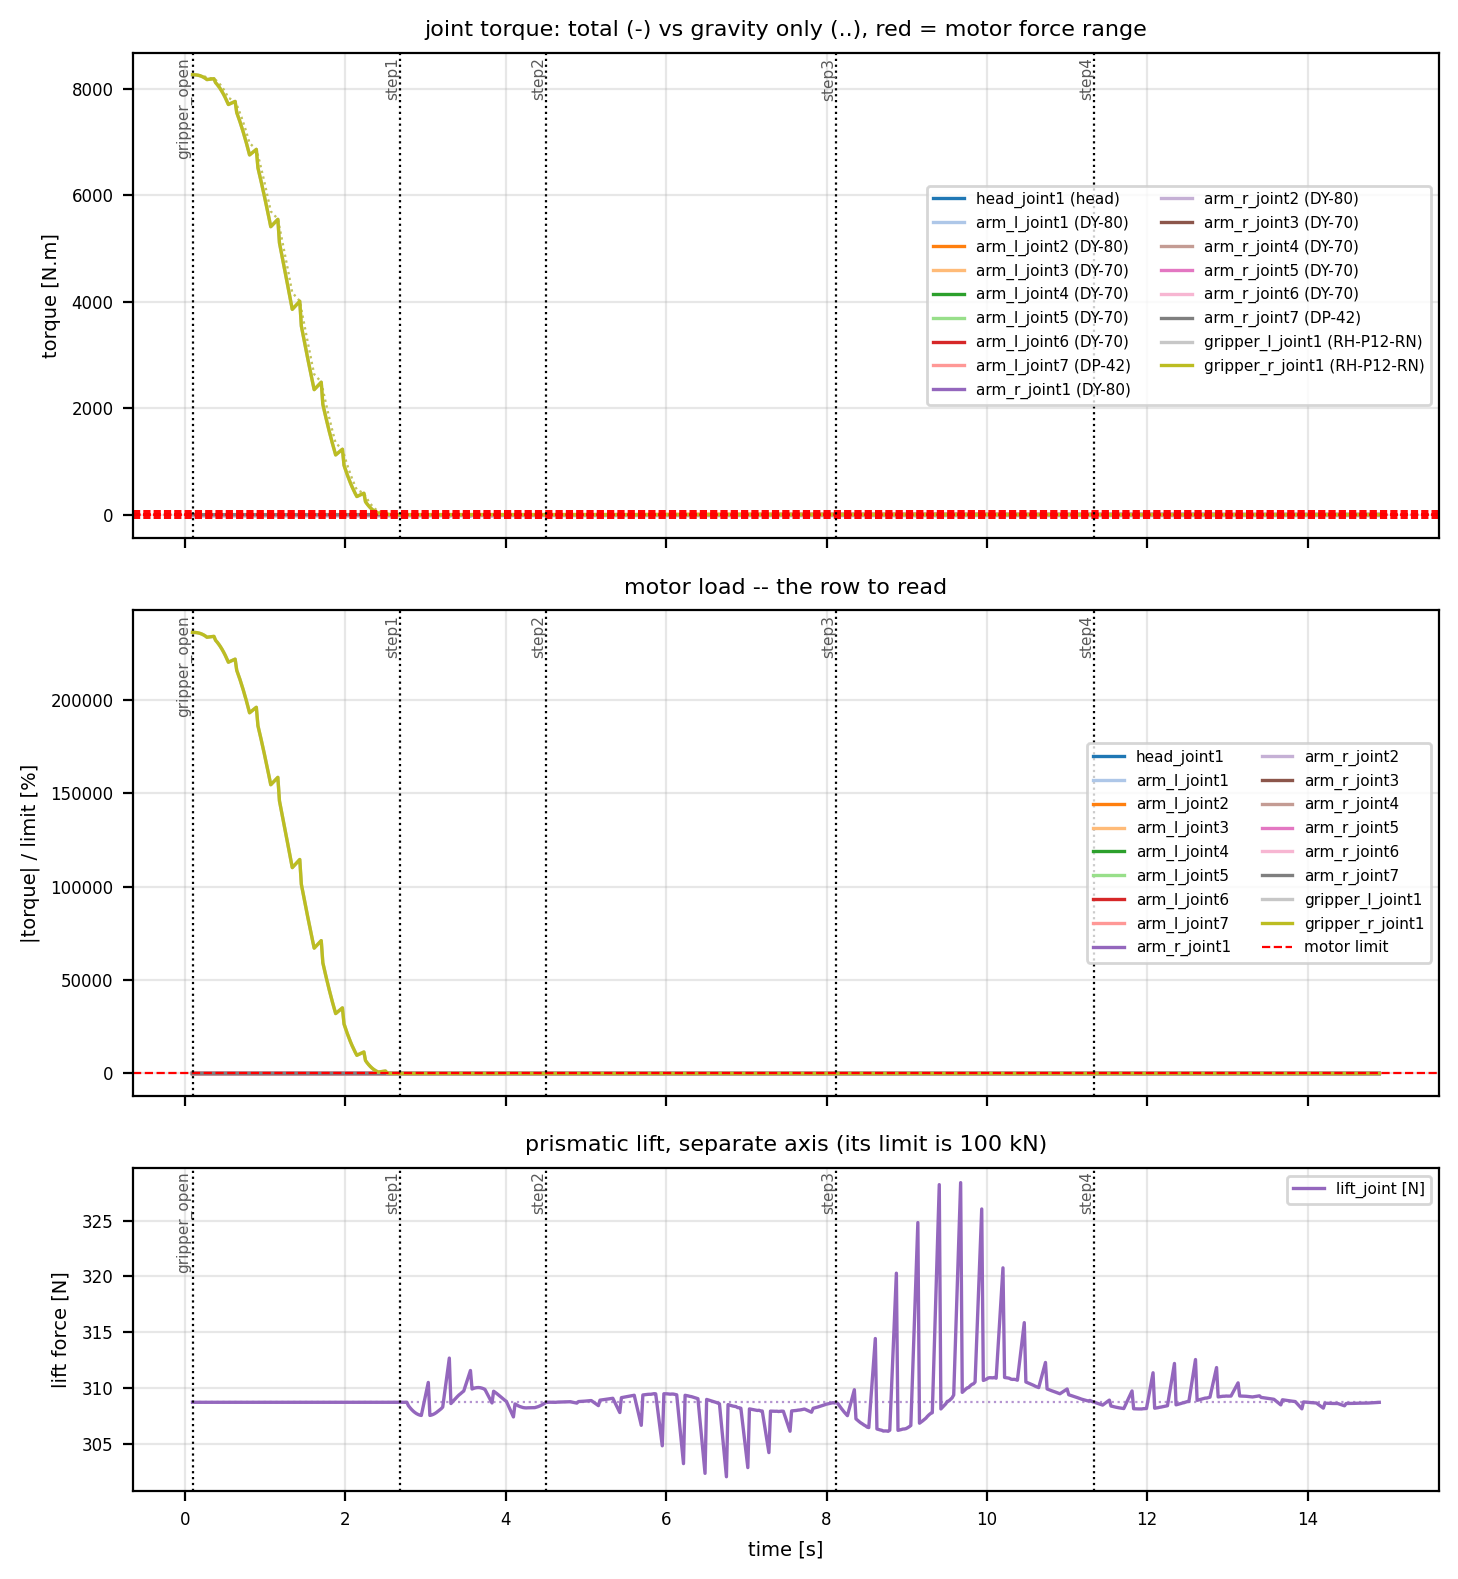


joint                 motor    limit peak |tau|   load gravity share  worst at
------------------------------------------------------------------------------------
gripper_r_joint1  RH-P12-RN     3.5N.m  8260.10236002.8%         100%  t=0.09s [gripper_open]
gripper_l_joint1  RH-P12-RN     3.5N.m  8260.10236002.8%         100%  t=0.09s [gripper_open]
arm_l_joint4          DY-70    31.7N.m    17.67  55.7%          46%  t=9.67s [step3]
arm_r_joint4          DY-70    31.7N.m    17.60  55.5%          46%  t=9.67s [step3]
arm_r_joint1          DY-80    61.4N.m    21.81  35.5%          67%  t=3.30s [step1]
arm_l_joint3          DY-70    31.7N.m     8.46  26.7%          27%  t=6.22s [step2]
arm_r_joint3          DY-70    31.7N.m     8.43  26.6%          27%  t=6.22s [step2]
arm_l_joint2          DY-80    61.4N.m    15.59  25.4%          63%  t=9.67s [step3]
arm_r_joint2          DY-80    61.4N.m    15.47  25.2%          64%  t=9.67s [step3]
arm_l_joint1          DY-80    61.4N.m    11.78  19.

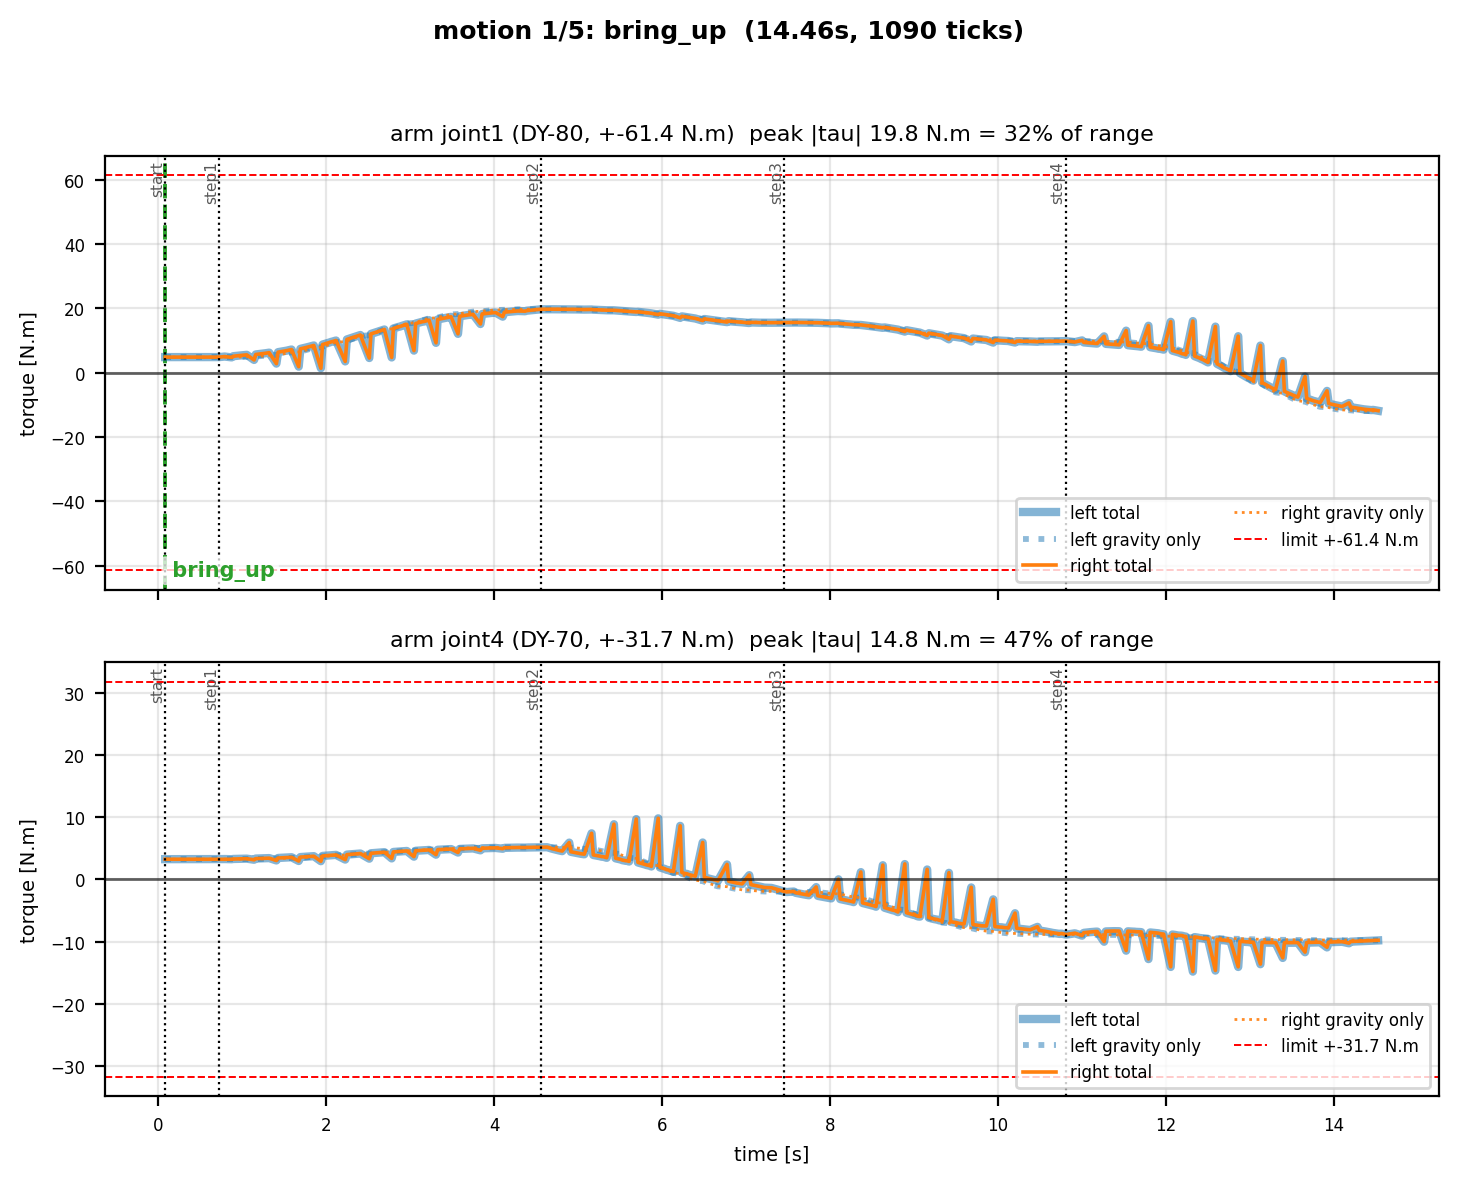


[bring_up]
joint            peak |tau|   load  grav min  grav max   swing  zero crossings
--------------------------------------------------------------------------------
arm_l_joint1        19.76Nm  32.2%     -11.9      19.8    31.7  step4 (t=13.0s)
arm_r_joint1        19.78Nm  32.2%     -11.9      19.8    31.7  step4 (t=13.0s)
arm_l_joint4        14.82Nm  46.8%      -9.8       5.2    14.9  step2 (t=6.6s)
arm_r_joint4        14.80Nm  46.7%      -9.8       5.2    14.9  step2 (t=6.6s)
--------------------------------------------------------------------------------


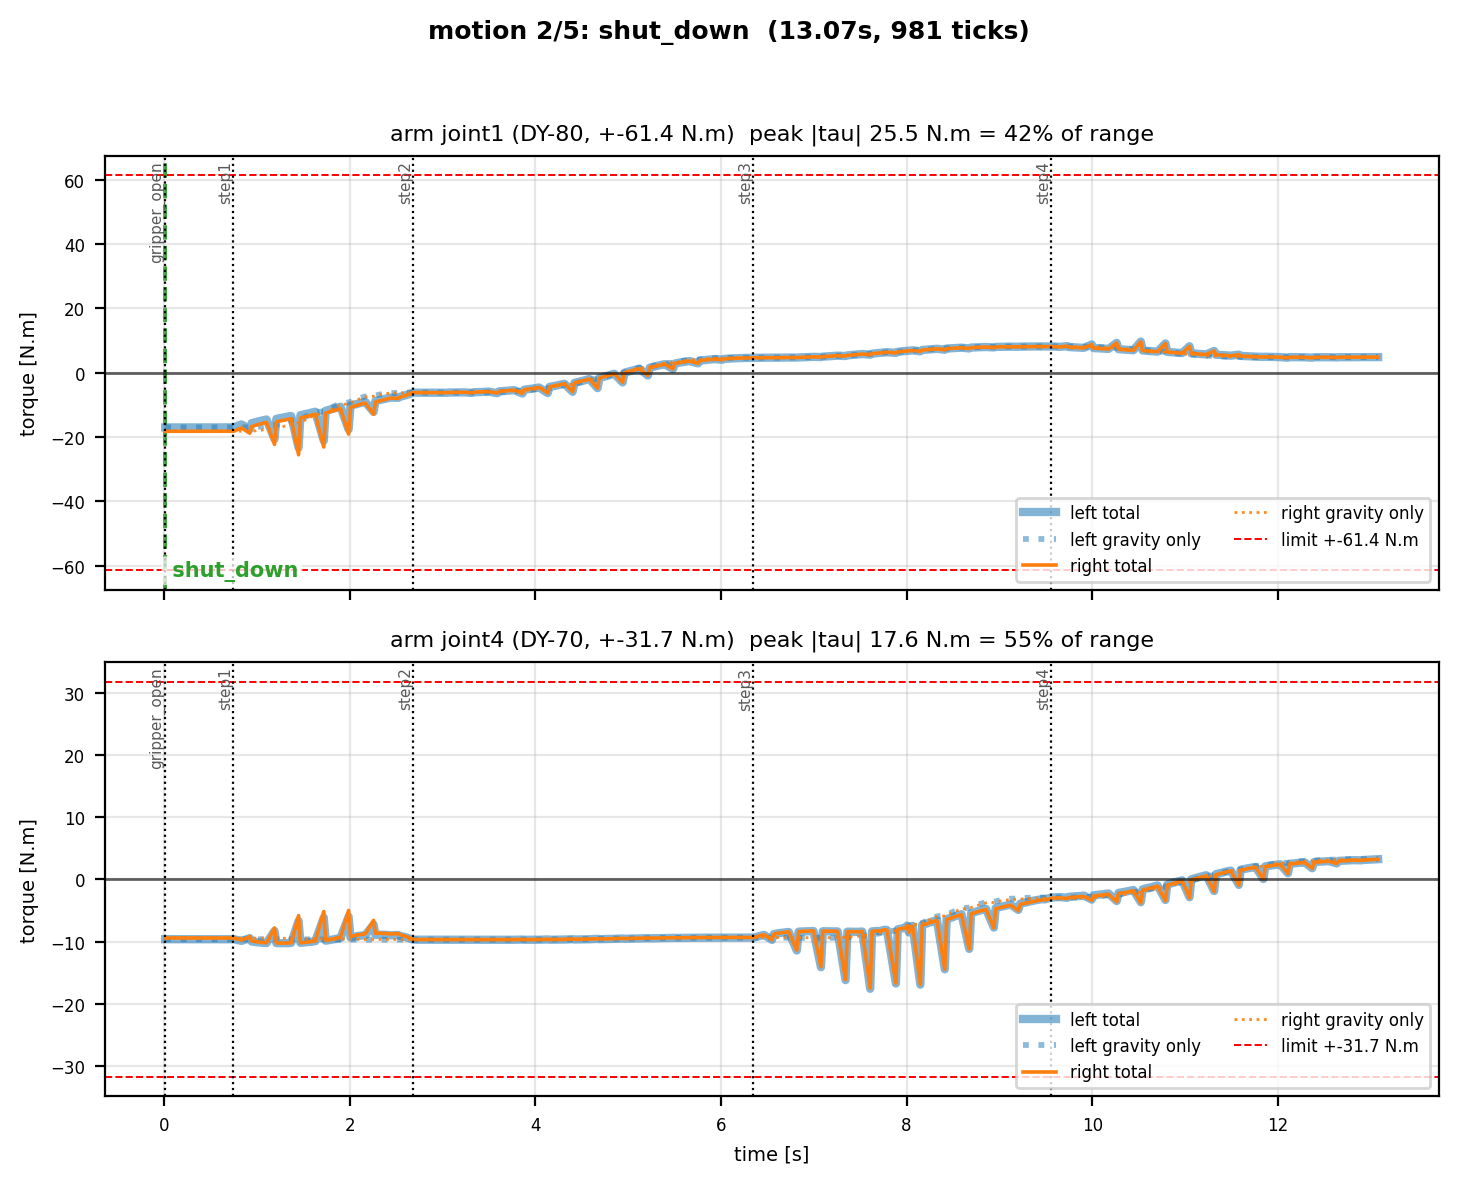


[shut_down]
joint            peak |tau|   load  grav min  grav max   swing  zero crossings
--------------------------------------------------------------------------------
arm_l_joint1        23.32Nm  38.0%     -17.0       8.2    25.2  step2 (t=5.1s)
arm_r_joint1        25.52Nm  41.6%     -18.2       8.2    26.4  step2 (t=5.1s)
arm_l_joint4        17.57Nm  55.4%      -9.7       3.2    12.9  step4 (t=11.3s)
arm_r_joint4        17.50Nm  55.2%      -9.7       3.2    12.9  step4 (t=11.3s)
--------------------------------------------------------------------------------


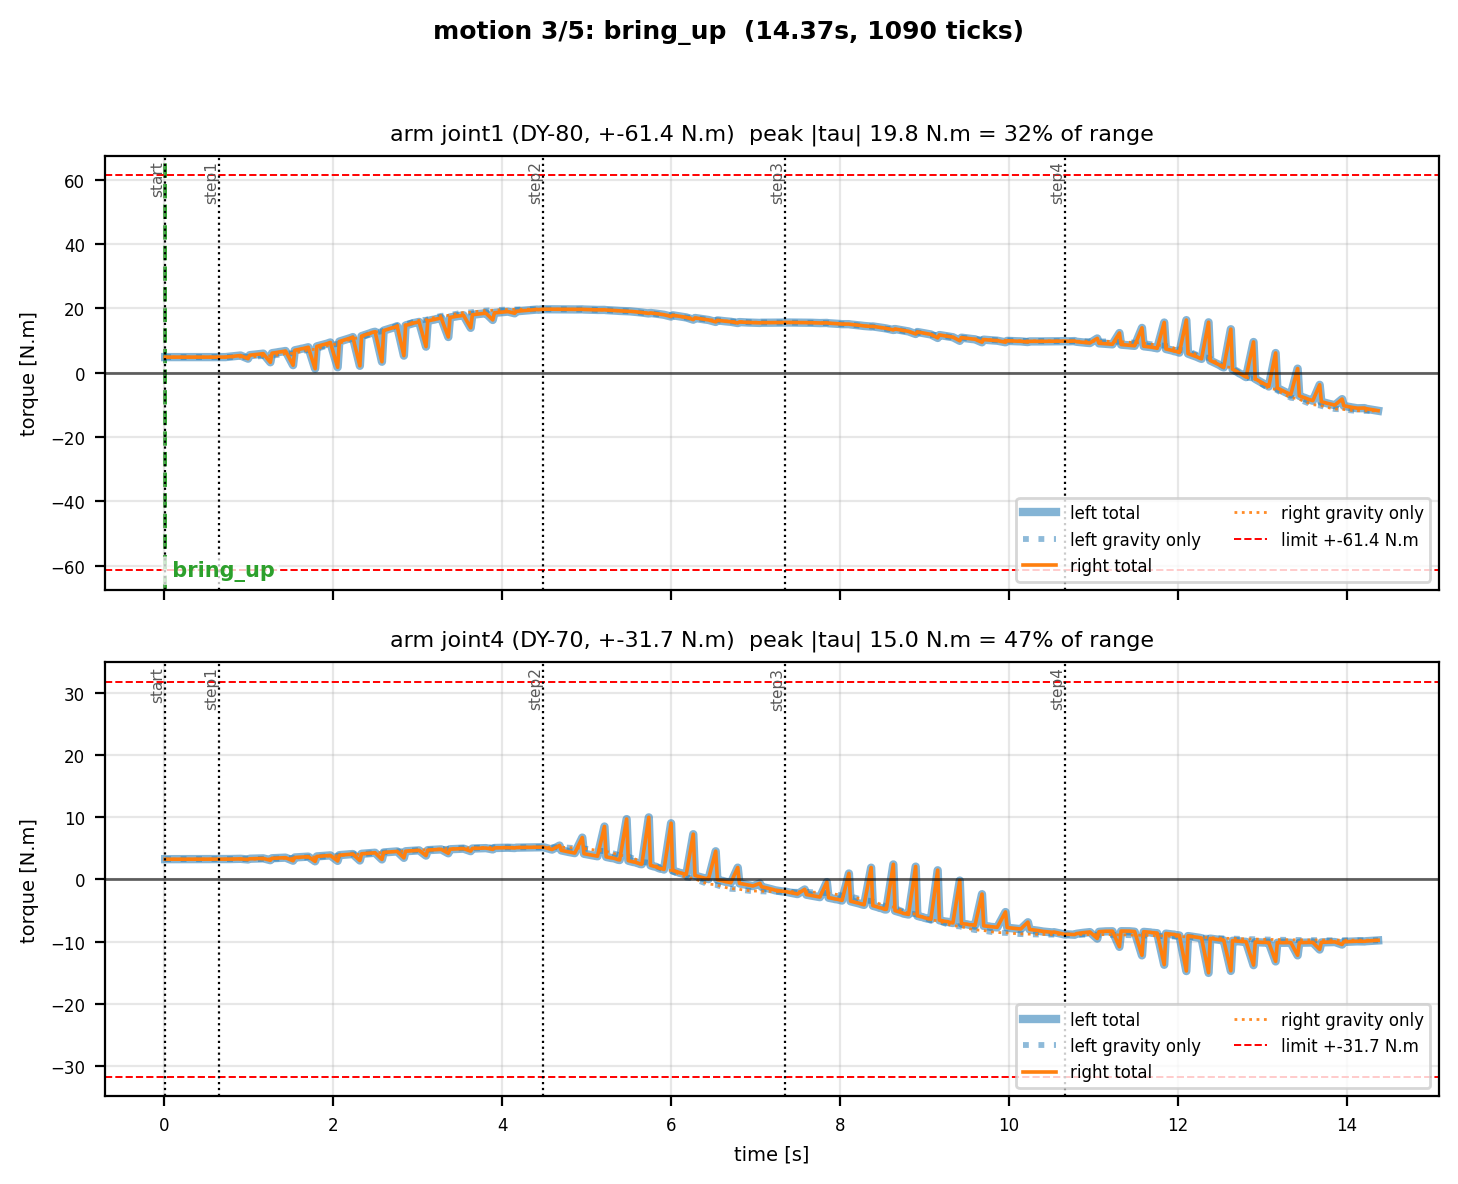


[bring_up]
joint            peak |tau|   load  grav min  grav max   swing  zero crossings
--------------------------------------------------------------------------------
arm_l_joint1        19.76Nm  32.2%     -11.9      19.8    31.7  step4 (t=12.8s)
arm_r_joint1        19.78Nm  32.2%     -11.9      19.8    31.7  step4 (t=12.8s)
arm_l_joint4        15.03Nm  47.4%      -9.8       5.2    14.9  step2 (t=6.4s)
arm_r_joint4        15.01Nm  47.3%      -9.8       5.2    14.9  step2 (t=6.4s)
--------------------------------------------------------------------------------


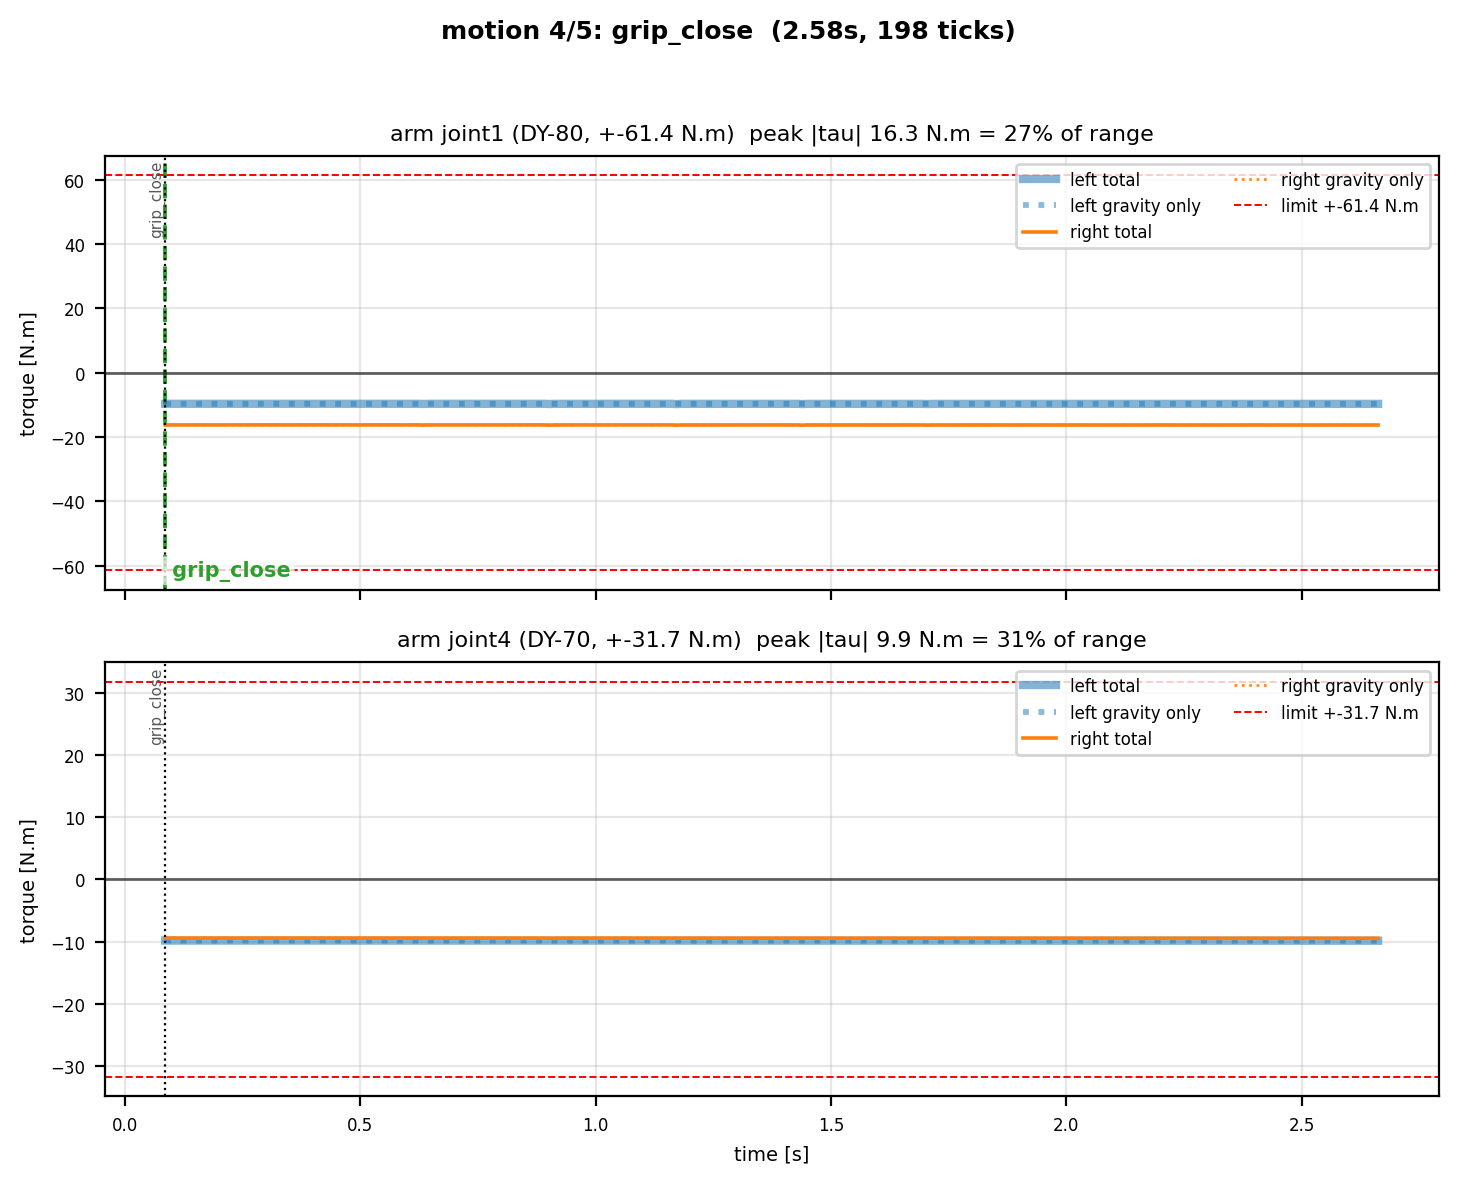


[grip_close]
joint            peak |tau|   load  grav min  grav max   swing  zero crossings
--------------------------------------------------------------------------------
arm_l_joint1         9.75Nm  15.9%      -9.7      -9.7     0.0  none
arm_r_joint1        16.32Nm  26.6%     -16.2     -16.2     0.0  none
arm_l_joint4         9.86Nm  31.1%      -9.9      -9.8     0.0  none
arm_r_joint4         9.46Nm  29.8%      -9.5      -9.4     0.0  none
--------------------------------------------------------------------------------


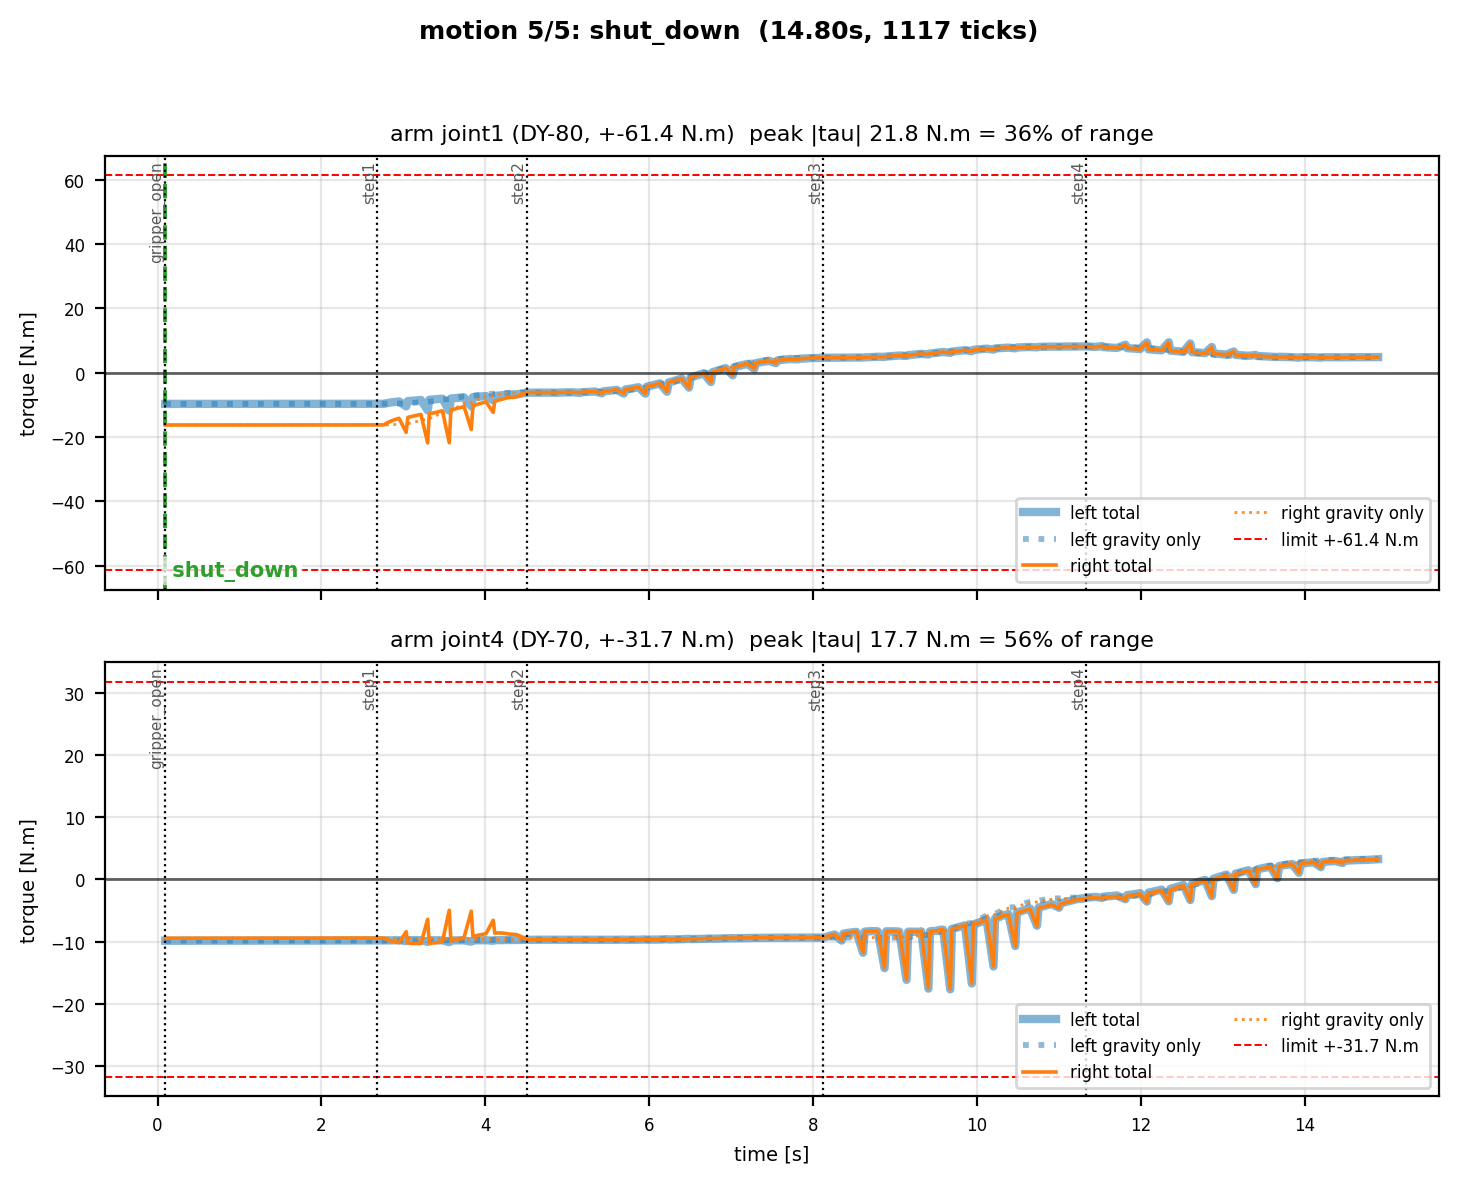


[shut_down]
joint            peak |tau|   load  grav min  grav max   swing  zero crossings
--------------------------------------------------------------------------------
arm_l_joint1        11.78Nm  19.2%      -9.7       8.2    17.9  step2 (t=6.9s)
arm_r_joint1        21.81Nm  35.5%     -16.2       8.2    24.4  step2 (t=6.9s)
arm_l_joint4        17.67Nm  55.7%      -9.9       3.2    13.1  step4 (t=13.0s)
arm_r_joint4        17.60Nm  55.5%      -9.7       3.2    12.9  step4 (t=13.1s)
--------------------------------------------------------------------------------
swing = the full range of the gravity torque. A joint whose gravity curve runs
from negative to positive drags that whole span across the gear backlash.
motion              : shut_down  (gripper_open -> step1 -> step2 -> step3 -> step4)
ticks               : 1117 over 14.89 s
loop timing         : dt median 10.0 ms (nominal 10.0 ms) -> effective 100.0 Hz
rate limit engaged  : 0 / 1117 ticks (0.0%), max dq/dq_max 1.000x
joint

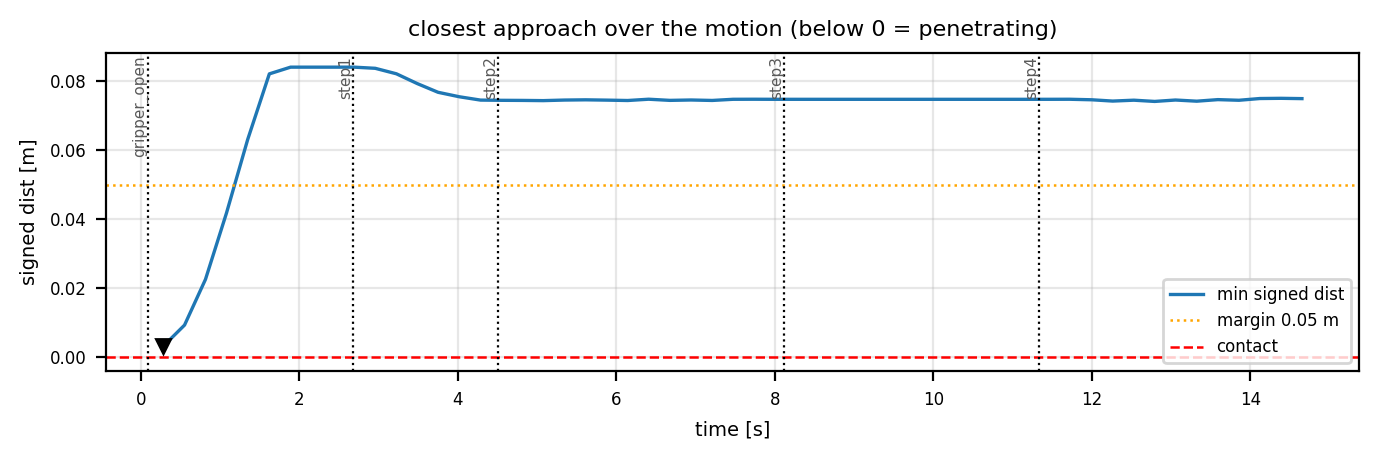


verdict: OK -- the planned trajectory respected both limits on its own.


In [11]:
# Analysis -- per-joint position/velocity plots, and the two clipping stages kept apart

if len(exec_log["t"]) < 3:
    raise RuntimeError("No motion logged. Run the loop cell and trigger a Motion command first.")

log_t     = np.array(exec_log["t"], dtype=np.float64)
log_q_cmd = np.array(exec_log["q_cmd"], dtype=np.float64)
log_q_use = np.array(exec_log["q_use"], dtype=np.float64)
log_dt    = np.array(exec_log["dt"], dtype=np.float64)

# Finite-difference velocity, using each tick's own dt rather than a nominal 1/hz.
dt_step = np.maximum(np.diff(log_t), 1e-9)[:, None]
qv_use  = np.diff(log_q_use, axis=0) / dt_step
qv_cmd  = np.diff(log_q_cmd, axis=0) / dt_step

# Plot only the joints that actually moved; all 19 at once is unreadable.
moved_idxs = np.where(np.max(np.abs(log_q_use - log_q_use[0]), axis=0) > 1e-6)[0]
if len(moved_idxs) == 0:
    moved_idxs = np.arange(min(2, log_q_use.shape[1]))

pri_joint_name_set = set(env.pri_joint_names)


def distinct_colors(n):
    """matplotlib's default cycle holds 10 colours and these plots routinely draw
    13-19 curves, so the 11th silently repeats the 1st. Two joints in the same
    colour read as one joint doing two contradictory things -- tab20 has enough."""
    palette = plt.get_cmap("tab20").colors
    return [palette[i % len(palette)] for i in range(n)]


def to_display(values, joint_name):
    """rad -> deg, m -> mm. Radians are unreadable on a chart: 1.57 is a right
    angle and nothing about the number says so."""
    if joint_name in pri_joint_name_set:
        return 1e3 * np.asarray(values), "mm"
    return np.rad2deg(np.asarray(values)), "deg"

# Segment spans (label, t_start, t_end). Marking only where a change happened
# leaves an 8-leg shut_down as 7 anonymous vertical lines, with no way to tell
# which one is the aggressive leg; the spans are what let each be named on the
# axis and shaded. Written as a function because 4e re-derives it for each of
# the motions it charts.
def segment_spans_of(labels, t_rows):
    labels, spans, span_start = list(labels), [], 0
    for i in range(1, len(labels) + 1):
        if i == len(labels) or labels[i] != labels[span_start]:
            spans.append((labels[span_start], float(t_rows[span_start]), float(t_rows[i - 1])))
            span_start = i
    return spans


segment_spans = segment_spans_of(exec_log["segment"], log_t)

# The Cartesian pre-step of shut_down, highlighted everywhere: it is the one
# segment whose goal was not a stored waypoint but an IK solve made at command
# time, and therefore the one that can surprise.
HIGHLIGHT_SEGMENT = "wrist_lift"

def draw_segments(ax, spans=None):
    """Name every segment on the time axis and shade the wrist-lift leg."""
    for name, t0, t1 in (segment_spans if spans is None else spans):
        ax.axvline(t0, color='k', ls=':', lw=0.8)
        if name == HIGHLIGHT_SEGMENT:
            ax.axvspan(t0, t1, color='tab:orange', alpha=0.13, lw=0, zorder=0)
        ax.text(t0, 0.99, name, transform=ax.get_xaxis_transform(), rotation=90,
                va='top', ha='right', fontsize=5.5, color='0.35')


def draw_motion_start(ax, t0, name):
    """Mark the instant the Motion command was pressed, named by the command.

    The dotted segment ticks say which LEG is running; this says which BUTTON
    produced them -- shut_down, bring_up_origin -- which is what you actually
    clicked. Drawn along the bottom so it does not collide with the segment
    names running down from the top."""
    ax.axvline(t0, color='tab:green', ls='--', lw=1.4, zorder=1)
    ax.text(t0, 0.02, " %s" % name, transform=ax.get_xaxis_transform(),
            va='bottom', ha='left', fontsize=7.5, color='tab:green',
            fontweight='bold', zorder=3,
            bbox=dict(boxstyle='round,pad=0.18', fc='white', ec='none', alpha=0.75))


# Every motion of this session, oldest first. The loop cell clears exec_log when
# a new command starts, so exec_log by itself is only the LAST motion; it stashes
# the previous ones in exec_log_history first, and 4e charts each of them. Every
# other section here stays on the last motion, which is the one being tuned.
motion_runs = [past for past in globals().get("exec_log_history", [])
               if len(past["t"]) >= 3]
motion_runs.append({"label"  : exec_log_label or "motion",
                    "t"      : log_t,
                    "q_use"  : log_q_use,
                    "segment": list(exec_log["segment"])})

# ---------------------------------------------------------------------------
# 1) Position
# ---------------------------------------------------------------------------
plt.figure(figsize=(7, 3))
moved_colors = distinct_colors(len(moved_idxs))
for color, idx in zip(moved_colors, moved_idxs):
    plt.plot(log_t, log_q_cmd[:, idx], '--', lw=1.0, color=color,
             label=f"{command_joint_names[idx]} cmd")
    plt.plot(log_t, log_q_use[:, idx], '-', lw=1.2, color=color,
             label=f"{command_joint_names[idx]} use")
draw_segments(plt.gca())
plt.xlabel("time [s]", fontsize=7); plt.ylabel("qpos [rad, m]", fontsize=7)
plt.title(f"{exec_log_label}: command (--) vs executed (-)", fontsize=8)
plt.legend(fontsize=6); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ---------------------------------------------------------------------------
# 2) Velocity, with the limit drawn in
# ---------------------------------------------------------------------------
plt.figure(figsize=(7, 3))
for color, idx in zip(moved_colors, moved_idxs):
    plt.plot(log_t[1:], qv_cmd[:, idx], '--', lw=1.0, color=color,
             label=f"{command_joint_names[idx]} cmd")
    plt.plot(log_t[1:], qv_use[:, idx], '-', lw=1.2, color=color,
             label=f"{command_joint_names[idx]} use")
    plt.axhline( joint_speed_limits[idx], color='r', ls=':', lw=0.8)
    plt.axhline(-joint_speed_limits[idx], color='r', ls=':', lw=0.8)
plt.xlabel("time [s]", fontsize=7); plt.ylabel("qvel [rad/s, m/s]", fontsize=7)
plt.title("velocity: finite difference (red dotted = v_max)", fontsize=8)
plt.legend(fontsize=6); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ---------------------------------------------------------------------------
# 3) Where the wrists actually went -- the Cartesian path behind the joint plots
# ---------------------------------------------------------------------------
# `wrist_lift` is the only segment specified in Cartesian space ("raise world z
# to the height `step4` has") but executed in joint space, so the qpos plots
# above cannot answer the question that step exists to answer: how far, and how
# fast, did the wrist actually go up? Replay the logged q_use through FK to find
# out -- `env.forward` is kinematics only, so this costs nothing, and the pose
# the cell started from is put back afterwards.
n_fk_max  = 600                                  # FK on every tick of a 30s log is wasteful
fk_stride = max(1, int(np.ceil(len(log_t) / n_fk_max)))
fk_idxs   = np.arange(0, len(log_t), fk_stride)
fk_t      = log_t[fk_idxs]

q_before = env.get_qpos(joint_names=command_joint_names).copy()
try:
    wrist_p = {hand_type: np.zeros((len(fk_idxs), 3)) for hand_type in SG2_HAND_TYPES}
    for row, idx in enumerate(fk_idxs):
        env.forward(q=log_q_use[idx], joint_names=command_joint_names)
        for hand_type in SG2_HAND_TYPES:
            wrist_p[hand_type][row] = t2p(get_sg2_wrist_control_T(env, hand_type))
finally:
    env.forward(q=q_before, joint_names=command_joint_names)

fig, axes = plt.subplots(2, 1, figsize=(7, 4.2), sharex=True)
for hand_type in SG2_HAND_TYPES:
    z  = wrist_p[hand_type][:, 2]
    vz = np.gradient(z, fk_t)                    # vertical speed of the wrist itself
    axes[0].plot(fk_t, z,  '-', lw=1.3, label=f"{hand_type} wrist z")
    axes[1].plot(fk_t, vz, '-', lw=1.3, label=f"{hand_type} wrist vz")
for ax in axes:
    draw_segments(ax)
    ax.grid(alpha=0.3); ax.legend(fontsize=6)
axes[1].axhline(0.0, color='k', lw=0.6)
axes[0].set_ylabel("wrist world z [m]", fontsize=7)
axes[1].set_ylabel("wrist vz [m/s]", fontsize=7)
axes[1].set_xlabel("time [s]", fontsize=7)
axes[0].set_title("wrist height and vertical speed (orange band = wrist_lift)", fontsize=8)
plt.tight_layout(); plt.show()

lift_spans = [span for span in segment_spans if span[0] == HIGHLIGHT_SEGMENT]
if len(lift_spans) == 0:
    print("wrist lift          : no wrist_lift segment in this motion -- either it was not a "
          "shut_down, or both wrists were already at or above the lift height.")
else:
    _, lift_t0, lift_t1 = lift_spans[0]
    in_lift = (fk_t >= lift_t0) & (fk_t <= lift_t1)
    print(f"wrist lift          : t={lift_t0:.2f}..{lift_t1:.2f}s "
          f"({lift_t1 - lift_t0:.2f}s of a {log_t[-1]:.2f}s motion)")
    for hand_type in SG2_HAND_TYPES:
        z = wrist_p[hand_type][in_lift, 2]
        if len(z) < 2:
            continue
        vz = np.gradient(z, fk_t[in_lift])
        # The rise is not a constant "small lift": it is (step4 wrist z) - (wrist z
        # at command time), so a hand left down by the table gets tens of cm.
        print(f"  {hand_type:<5s} z {z[0]:.3f} -> {z[-1]:.3f} m (rise {z[-1] - z[0]:+.3f} m), "
              f"peak |vz| {np.max(np.abs(vz)):.3f} m/s")

# How straight was each leg? Both planners end a segment at the same wrist pose,
# so the endpoints carry no information -- the bulge away from the chord between
# them is the whole difference between one route and another.
print()
print(f"{'segment':>14s} {'hand':>6s} {'chord [m]':>10s} {'bulge [mm]':>11s} {'bulge/chord':>12s}")
print("-" * (14 + 43))
for name, t0, t1 in segment_spans:
    m = (fk_t >= t0) & (fk_t <= t1)
    if int(np.sum(m)) < 3:
        continue
    for hand_type in SG2_HAND_TYPES:
        bulge, chord = path_straightness(wrist_p[hand_type][m])
        if chord < 1e-4:
            continue
        print(f"{name:>14s} {hand_type:>6s} {chord:10.3f} {1e3 * bulge:11.1f} "
              f"{100.0 * bulge / chord:11.1f}%")

# ---------------------------------------------------------------------------
# 4) Per-segment breakdown -- which leg of the motion is the aggressive one
# ---------------------------------------------------------------------------
# `estimate_duration` returns the SHORTEST T that still respects v_max and a_max,
# so every segment is planned to run at its ceiling. "Aggressive" is therefore
# never a limit violation here (v/v_max stays ~1.0 throughout); it is a segment
# whose joint-space displacement is much larger than its Cartesian displacement
# looks. This table names the joint that set the pace and how far it travelled.
# Both ratios are finite differences of the executed qpos and carry the same
# noise as the plots above -- read them as "about 1.0 or not", not to 3 digits.
qa_use = np.diff(qv_use, axis=0) / dt_step[1:]

print()
print(f"{'segment':>14s} {'T [s]':>6s} {'ticks':>6s} {'v/v_max':>8s} {'a/a_max':>8s} "
      f"{'pace-setting joint':>22s} {'its travel':>12s}")
print("-" * 84)
for name, t0, t1 in segment_spans:
    m = (log_t >= t0) & (log_t <= t1)
    if int(np.sum(m)) < 3:
        print(f"{name:>14s} {t1 - t0:6.2f} {int(np.sum(m)):6d} {'-':>8s} {'-':>8s}")
        continue
    v_ratio = np.abs(qv_use[m[1:]]) / joint_speed_limits
    a_ratio = np.abs(qa_use[m[2:]]) / joint_acc_limits
    j       = int(np.argmax(np.max(v_ratio, axis=0)))
    travel  = float(np.max(np.abs(log_q_use[m][:, j] - log_q_use[m][0, j])))
    travel_text = (f"{1e3 * travel:7.1f} mm" if command_joint_names[j] in pri_joint_name_set
                   else f"{np.rad2deg(travel):7.1f} deg")
    print(f"{name:>14s} {t1 - t0:6.2f} {int(np.sum(m)):6d} "
          f"{np.max(v_ratio):8.2f} {np.max(a_ratio):8.2f} "
          f"{command_joint_names[j]:>22s} {travel_text:>12s}")

# ---------------------------------------------------------------------------
# 4b) What the planner decided, segment by segment
# ---------------------------------------------------------------------------
# `endpoint_gap` and `ik_err_max` exist only at plan time and are gone by the
# time the motion is over, so the executor keeps them. The gap is not an error:
# a 7-DoF arm has a null space, so "put the wrist here" does not name a single
# joint pose. It IS the signal for whether a segment's goal was a Cartesian
# instruction at all -- small on wrist_lift, large on the stow waypoints.
if len(getattr(executor, "plan_reports", [])) > 0:
    print()
    print(f"{'segment':>14s} {'route':>12s} {'T [s]':>6s} {'D_lin':>7s} {'D_ang':>7s} "
          f"{'ik err [m]':>11s} {'gap [deg]':>10s}  note")
    print("-" * 92)
    for report in executor.plan_reports:
        route = "cartesian" if report["cartesian"] else "joint-space"
        print(f"{report['segment']:>14s} {route:>12s} {report['duration']:6.2f} "
              f"{report['D_lin']:7.3f} {np.rad2deg(report['D_ang']):6.1f}d "
              f"{report['ik_err_max']:11.4f} {np.rad2deg(report['endpoint_gap']):9.1f}d  "
              f"{report['reason']}")
    print("-" * 92)
    print("gap = |IK pose at the end of the segment - the stored waypoint|. Tens of degrees on a")
    print("      stow leg means that leg belongs on the joint-space planner: set CARTESIAN_SEGMENTS.")

# ---------------------------------------------------------------------------
# 4d) Per-segment joint journey -- from the pose it started at to the pose it
#     was aimed at, one panel per segment
# ---------------------------------------------------------------------------
# Section 1 draws the whole motion as one continuous timeline, which answers
# "what happened" but not "did this segment do what it was asked". Two things
# only show up when a segment is drawn on its own:
#
#   - the GOAL, as a dashed line. On this planner the segment does not end on
#     it: the IK arrives at a pose with the right wrist frame, not at the stored
#     waypoint, and the leftover is `endpoint_gap` from section 4b. A curve that
#     stops short of its dashed line is that gap, made visible per joint instead
#     of collapsed into one worst-case number.
#   - whether the joints move TOGETHER. Every joint shares one progress scalar
#     s(t), so within a panel all curves must start, inflect and settle at the
#     same instants; only their vertical scales differ. A curve that moves while
#     the others are flat means the planner did not do what it says.
#
# The x axis is segment-local time, so panels are directly comparable.
JOURNEY_TRAVEL_MIN = np.deg2rad(0.5)     # joints quieter than this are not drawn

plan_reports = list(getattr(executor, "plan_reports", []))

journey      = []
journey_skip = []
for seg_idx, (name, t0, t1) in enumerate(segment_spans):
    mask = (log_t >= t0) & (log_t <= t1)
    if int(np.sum(mask)) < 3:
        continue
    q_seg   = log_q_use[mask]
    travel  = np.max(np.abs(q_seg - q_seg[0]), axis=0)
    joints  = np.where(travel > JOURNEY_TRAVEL_MIN)[0]
    # The report list is appended in planning order, which is the order the
    # spans appear in; guard the pairing by name so a cancelled motion (one
    # extra planned segment, never executed) cannot shift every panel's target.
    report = (plan_reports[seg_idx]
              if seg_idx < len(plan_reports) and plan_reports[seg_idx]["segment"] == name
              else None)
    if len(joints) == 0:
        # A gripper-only or already-at-goal segment. Drawing an empty panel for
        # it would push the informative ones into a smaller grid for nothing.
        journey_skip.append(name)
        continue
    journey.append({"name": name, "t": log_t[mask] - t0, "q": q_seg,
                    "joints": joints, "q_goal": None if report is None else report.get("q_goal")})

if len(journey) == 0:
    print("per-segment journey: nothing long enough to plot.")
else:
    n_col = min(3, len(journey))
    n_row = int(np.ceil(len(journey) / n_col))
    fig, axes = plt.subplots(n_row, n_col, figsize=(3.4 * n_col, 2.7 * n_row), squeeze=False)
    for ax in axes.ravel()[len(journey):]:
        ax.axis("off")
    for panel, ax in zip(journey, axes.ravel()):
        panel_colors = distinct_colors(len(panel["joints"]))
        panel_units  = set()
        for color, idx in zip(panel_colors, panel["joints"]):
            q_disp, unit = to_display(panel["q"][:, idx], command_joint_names[idx])
            panel_units.add(unit)
            ax.plot(panel["t"], q_disp, '-', lw=1.3, color=color,
                    label=command_joint_names[idx].replace("arm_", "").replace("joint", "j"))
            if panel["q_goal"] is not None:
                # Dashed = where this segment was AIMED. The distance from the
                # curve's endpoint to it is this joint's share of endpoint_gap.
                goal_disp, _ = to_display(panel["q_goal"][idx], command_joint_names[idx])
                ax.axhline(goal_disp, color=color, ls='--', lw=0.8, alpha=0.6)
            ax.plot(panel["t"][-1], q_disp[-1], 'o', ms=3.5, color=color)
        ax.set_title(f"{panel['name']}  ({panel['t'][-1]:.2f}s)", fontsize=8)
        ax.set_xlabel("time in segment [s]", fontsize=6.5)
        ax.set_ylabel("qpos [%s]" % ", ".join(sorted(panel_units)), fontsize=6.5)
        ax.tick_params(labelsize=6); ax.grid(alpha=0.3); ax.legend(fontsize=5.5, ncol=2)
    fig.suptitle("per segment: start -> reached (o), dashed = the goal it was aimed at", fontsize=9)
    plt.tight_layout(); plt.show()

    # The same thing as numbers, for the joint that fell furthest short in each
    # segment. `residual` is what section 4b reports as endpoint_gap.
    print()
    print(f"{'segment':>14}{'joint':>16}{'start':>9}{'reached':>9}{'goal':>9}"
          f"{'travel':>9}{'residual':>10}")
    print("-" * 76)
    for panel in journey:
        if panel["q_goal"] is None:
            # Only happens when the log predates the plan report, e.g. the loop
            # was re-run without re-running the executor cell.
            print(f"{panel['name']:>14}{'no goal recorded':>16}")
            continue
        residual = np.abs(panel["q"][-1] - panel["q_goal"])
        idx = int(panel["joints"][np.argmax(residual[panel["joints"]])])
        to_unit = (lambda v: 1e3 * v) if command_joint_names[idx] in pri_joint_name_set else np.rad2deg
        unit    = "mm" if command_joint_names[idx] in pri_joint_name_set else "deg"
        print(f"{panel['name']:>14}{command_joint_names[idx]:>16}"
              f"{to_unit(panel['q'][0, idx]):9.1f}{to_unit(panel['q'][-1, idx]):9.1f}"
              f"{to_unit(panel['q_goal'][idx]):9.1f}"
              f"{to_unit(abs(panel['q'][-1, idx] - panel['q'][0, idx])):9.1f}"
              f"{to_unit(residual[idx]):9.1f} {unit}")
    print("-" * 76)
    print("residual = how far the worst joint of that segment stopped short of the stored")
    print("waypoint. Not an error: a 7-DoF arm reaches the wrist pose with a whole family of")
    print("joint poses, and this route picks whichever one the IK walked into. Large and")
    print("growing across the fold-in legs is the signal to narrow CARTESIAN_SEGMENTS.")
    if len(journey_skip) > 0:
        print(f"not drawn (no joint moved more than {np.rad2deg(JOURNEY_TRAVEL_MIN):.1f} deg): "
              f"{', '.join(journey_skip)}")
# ---------------------------------------------------------------------------
# 4c) Joint torque and motor load
# ---------------------------------------------------------------------------
# What the motors were asked for, by inverse dynamics on the trajectory that was
# actually executed:
#
#     tau = M(q) qddot + C(q, qdot) qdot + g(q)
#
# `mujoco.mj_inverse` solves exactly that from (qpos, qvel, qacc), so the whole
# section is a replay of the log with qvel and qacc taken from the finite
# differences already computed above.
#
# THIS IS A MODEL PREDICTION, NOT A MEASUREMENT. Nothing in this pipeline reads
# torque or current back from the robot -- `get_latest_robot_qpos` returns
# positions and nothing else. The numbers are only as good as the inertias in
# ffw_sg2.xml, and they carry no payload: whatever the gripper is holding is not
# in the model, so a loaded arm draws more than this says.
#
# The model's `damping` (20-30 N.m.s/rad on the arm joints) and `frictionloss`
# are simulation tuning for the position servo, not properties of the real
# joint -- at 0.3 rad/s the damping term alone would add ~9 N.m of pure fiction.
# They are zeroed for the duration of this section and restored afterwards.
# `armature` is kept: reflected rotor inertia is real.
import mujoco

mj_model, mj_data = env.model, env.data

# The motor behind each joint, straight out of the model's actuators. The family
# names come from the comments in ffw_sg2.xml; the force ranges are read from the
# compiled model, so they cannot drift out of sync with the XML.
MOTOR_FAMILY_BY_FORCE = {61.4: "DY-80", 31.7: "DY-70", 5.1: "DP-42",
                         10.0: "head", 3.5: "RH-P12-RN", 100000.0: "slider"}

joint_dof_idx   = {}
joint_force_max = {}
joint_motor     = {}
for actuator_idx in range(mj_model.nu):
    actuator_name = mujoco.mj_id2name(mj_model, mujoco.mjtObj.mjOBJ_ACTUATOR, actuator_idx)
    joint_idx     = int(mj_model.actuator_trnid[actuator_idx, 0])
    joint_name    = mujoco.mj_id2name(mj_model, mujoco.mjtObj.mjOBJ_JOINT, joint_idx)
    if joint_name not in command_joint_names:
        continue
    force_max = float(mj_model.actuator_forcerange[actuator_idx, 1])
    joint_dof_idx[joint_name]   = int(mj_model.jnt_dofadr[joint_idx])
    joint_force_max[joint_name] = force_max
    joint_motor[joint_name]     = MOTOR_FAMILY_BY_FORCE.get(round(force_max, 1), "?")

torque_joint_names = [name for name in command_joint_names if name in joint_dof_idx]
torque_dofs        = np.array([joint_dof_idx[name] for name in torque_joint_names])
torque_limits      = np.array([joint_force_max[name] for name in torque_joint_names])

# qvel / qacc aligned to every row of the log (the first samples have neither).
n_joint = log_q_use.shape[1]
qv_full = np.vstack([np.zeros((1, n_joint)), qv_use])
qa_full = np.vstack([np.zeros((2, n_joint)), qa_use])

q_before      = env.get_qpos(joint_names=command_joint_names).copy()
damping_save  = mj_model.dof_damping.copy()
friction_save = mj_model.dof_frictionloss.copy()
try:
    mj_model.dof_damping[:]      = 0.0
    mj_model.dof_frictionloss[:] = 0.0
    tau_total = np.zeros((len(fk_idxs), len(torque_dofs)))
    tau_grav  = np.zeros_like(tau_total)
    for row, idx in enumerate(fk_idxs):
        env.forward(q=log_q_use[idx], joint_names=command_joint_names)

        # Gravity alone: the torque needed just to hold this pose.
        mj_data.qvel[:] = 0.0
        mj_data.qacc[:] = 0.0
        mujoco.mj_inverse(mj_model, mj_data)
        tau_grav[row] = mj_data.qfrc_inverse[torque_dofs]

        # Gravity + inertia + Coriolis: what the move actually costs.
        mj_data.qvel[:] = 0.0
        mj_data.qacc[:] = 0.0
        mj_data.qvel[torque_dofs] = qv_full[idx][[command_joint_names.index(n) for n in torque_joint_names]]
        mj_data.qacc[torque_dofs] = qa_full[idx][[command_joint_names.index(n) for n in torque_joint_names]]
        mujoco.mj_inverse(mj_model, mj_data)
        tau_total[row] = mj_data.qfrc_inverse[torque_dofs]
finally:
    mj_model.dof_damping[:]      = damping_save
    mj_model.dof_frictionloss[:] = friction_save
    env.forward(q=q_before, joint_names=command_joint_names)

tau_ratio = np.abs(tau_total) / torque_limits[None, :]

# Plot only the joints that carry something; lift_joint's +-100 kN limit would
# flatten every arm curve on a shared axis, so it gets its own panel.
lift_cols = [j for j, name in enumerate(torque_joint_names) if name in pri_joint_name_set]
arm_cols  = [j for j, name in enumerate(torque_joint_names)
             if j not in lift_cols and np.max(np.abs(tau_total[:, j])) > 0.05]

fig, axes = plt.subplots(3, 1, figsize=(7.4, 8.0), sharex=True,
                         gridspec_kw={"height_ratios": [3, 3, 2]})

arm_colors = distinct_colors(len(arm_cols))
for color, j in zip(arm_colors, arm_cols):
    axes[0].plot(fk_t, tau_total[:, j], '-', lw=1.2, color=color,
                 label=f"{torque_joint_names[j]} ({joint_motor[torque_joint_names[j]]})")
    axes[0].plot(fk_t, tau_grav[:, j], ':', lw=0.8, color=color, alpha=0.7)
for limit in sorted({torque_limits[j] for j in arm_cols}):
    axes[0].axhline( limit, color='r', ls='--', lw=0.7)
    axes[0].axhline(-limit, color='r', ls='--', lw=0.7)
axes[0].set_ylabel("torque [N.m]", fontsize=7)
axes[0].set_title("joint torque: total (-) vs gravity only (..), red = motor force range", fontsize=8)

for color, j in zip(arm_colors, arm_cols):
    axes[1].plot(fk_t, 100.0 * tau_ratio[:, j], '-', lw=1.2, color=color,
                 label=torque_joint_names[j])
axes[1].axhline(100.0, color='r', ls='--', lw=0.8, label="motor limit")
axes[1].set_ylabel("|torque| / limit [%]", fontsize=7)
axes[1].set_title("motor load -- the row to read", fontsize=8)

for j in lift_cols:
    axes[2].plot(fk_t, tau_total[:, j], '-', lw=1.2, color='tab:purple',
                 label=f"{torque_joint_names[j]} [N]")
    axes[2].plot(fk_t, tau_grav[:, j], ':', lw=0.8, color='tab:purple', alpha=0.7)
axes[2].set_ylabel("lift force [N]", fontsize=7)
axes[2].set_xlabel("time [s]", fontsize=7)
axes[2].set_title("prismatic lift, separate axis (its limit is 100 kN)", fontsize=8)

for ax in axes:
    draw_segments(ax)
    ax.grid(alpha=0.3); ax.legend(fontsize=5.5, ncol=2)
plt.tight_layout(); plt.show()

print()
print(f"{'joint':<17}{'motor':>10}{'limit':>9}{'peak |tau|':>11}{'load':>7}"
      f"{'gravity share':>14}  worst at")
print("-" * 84)
for j in np.argsort(-np.max(tau_ratio, axis=0)):
    name  = torque_joint_names[j]
    worst = int(np.argmax(np.abs(tau_total[:, j])))
    unit  = "N" if name in pri_joint_name_set else "N.m"
    # How much of the peak was just holding the arm up: everything above it is
    # what the motion itself cost, and that is the part a faster plan increases.
    share = abs(tau_grav[worst, j]) / max(abs(tau_total[worst, j]), 1e-9)
    where = next((seg for seg, t0, t1 in segment_spans
                  if t0 <= fk_t[worst] <= t1), "-")
    print(f"{name:<17}{joint_motor[name]:>10}{torque_limits[j]:8.1f}{unit:<4}"
          f"{abs(tau_total[worst, j]):8.2f}{100.0 * tau_ratio[worst, j]:6.1f}%"
          f"{100.0 * share:12.0f}%  t={fk_t[worst]:.2f}s [{where}]")
print("-" * 84)
print("load = |tau| / the motor's force range in ffw_sg2.xml. MODEL PREDICTION, not")
print("measured, and with NO payload -- whatever the gripper holds is not in the model.")
worst_j = int(np.argmax(np.max(tau_ratio, axis=0)))
print(f"worst motor: {torque_joint_names[worst_j]} ({joint_motor[torque_joint_names[worst_j]]}) "
      f"at {100.0 * np.max(tau_ratio[:, worst_j]):.1f}% of its range")

# --- where the gravity load reverses -------------------------------------
# The sign of the gravity torque says which way gravity is trying to rotate the
# joint. It flips when the limb's centre of mass crosses the joint axis: on the
# way there the motor holds the arm up, past it the motor holds the arm back.
#
# At the crossing the torque passes through zero, so the gear train unloads and
# re-seats on the OPPOSITE tooth flank, taking up its backlash on the way. On a
# geared joint that is the classic source of an audible clunk, and it is exactly
# what a fold-in sequence does to the shoulder and the elbow.
#
# A magnitude plot hides this -- |tau| just dips -- which is why it gets its own
# readout. What matters is the SWING across the crossing: a joint that goes from
# -12 N.m to +20 N.m drags 32 N.m of load across the backlash.
TORQUE_ZERO_BAND = 0.02          # ignore crossings below 2% of the motor's range

print()
print(f"{'joint':<17}{'reversals':>10}{'swing':>10}  segments where the load reverses")
print("-" * 78)
n_reversal_total = 0
for j, name in enumerate(torque_joint_names):
    deadband = TORQUE_ZERO_BAND * torque_limits[j]
    signs    = np.sign(tau_grav[:, j])
    signs[np.abs(tau_grav[:, j]) < deadband] = 0.0      # near zero = no opinion
    crossings, last = [], 0.0
    for row, value in enumerate(signs):
        if value != 0.0:
            if last != 0.0 and value != last:
                crossings.append(row)
            last = value
    if len(crossings) == 0:
        continue
    n_reversal_total += len(crossings)
    where = []
    for row in crossings:
        where.append(next((seg for seg, t0, t1 in segment_spans
                           if t0 <= fk_t[row] <= t1), "?"))
    swing = float(np.max(tau_grav[:, j]) - np.min(tau_grav[:, j]))
    unit  = "N" if name in pri_joint_name_set else "N.m"
    print(f"{name:<17}{len(crossings):10d}{swing:8.1f}{unit:<3}  "
          + ", ".join(f"{w} (t={fk_t[r]:.1f}s)" for w, r in zip(where, crossings)))
print("-" * 78)
if n_reversal_total == 0:
    print("no gravity load reversal: every joint was pushed the same way throughout.")
else:
    print("A clunk heard at one of these times is backlash take-up, not a fault. It gets")
    print("worse the coarser the command stream is: check `loop timing` below -- at the")
    print("full robot_hz the motor crosses the backlash in one smooth profile instead of")
    print("being stepped across it. Slowing the segment (min_duration) also helps.")
    print("You can see the same thing on the torque plot above: the dotted gravity-only")
    print("curves are the ones that cross zero.")
# ---------------------------------------------------------------------------
# 4e) arm joint 1 and joint 4 alone, torque against time -- one figure per motion
# ---------------------------------------------------------------------------
# The panels above draw every loaded joint of the LAST motion at once, which is
# the right view for "is anything near its limit" and the wrong one for "what
# happened to the shoulder". joint1 and joint4 are the two that clunk on the
# fold-in, so they get charts to themselves -- and one full figure per motion
# command run this session, so pressing shut_down and then bring_up_origin gives
# a shut_down figure and a bring_up_origin figure rather than only the last one.
#
#   solid  = total torque (gravity + inertia + Coriolis) -- what the motor is asked for
#   dotted = gravity only  -- what it would take just to hold that pose still
#   the gap between them is the cost of the motion itself
#
# The zero line is drawn heavy on purpose. A dotted curve CROSSING it is the
# gravity-load reversal described just above: the moment arm has changed sides,
# the gear train unloads and re-seats on the opposite tooth flank. That crossing
# is the "두둑".
FOCUS_JOINT_NUMBERS = (1, 4)
FOCUS_ARM_PREFIXES  = ("arm_l_joint", "arm_r_joint")
SIDE_STYLE = {"arm_l_joint": ("tab:blue", "left"), "arm_r_joint": ("tab:orange", "right")}

focus_rows = []
for number in FOCUS_JOINT_NUMBERS:
    cols = [(prefix, torque_joint_names.index(prefix + str(number)))
            for prefix in FOCUS_ARM_PREFIXES
            if prefix + str(number) in torque_joint_names]
    if cols:
        focus_rows.append((number, cols))


def torque_replay(t_rows, q_rows, n_max=600):
    """Inverse dynamics along one logged trajectory -> (t, tau_total, tau_grav).

    Section 4c does this inline for the last motion; the older motions in
    exec_log_history need the same treatment, so it lives in a function. Same
    caveats as 4c: model prediction, no payload, damping and frictionloss zeroed
    for the duration and restored afterwards."""
    t_rows = np.asarray(t_rows, dtype=np.float64)
    q_rows = np.asarray(q_rows, dtype=np.float64)
    dt_row = np.maximum(np.diff(t_rows), 1e-9)[:, None]
    qv_row = np.vstack([np.zeros((1, q_rows.shape[1])), np.diff(q_rows, axis=0) / dt_row])
    qa_row = np.vstack([np.zeros((1, q_rows.shape[1])), np.diff(qv_row, axis=0) / dt_row])

    stride = max(1, int(np.ceil(len(t_rows) / n_max)))
    idxs   = np.arange(0, len(t_rows), stride)
    cols   = [command_joint_names.index(name) for name in torque_joint_names]

    q_keep        = env.get_qpos(joint_names=command_joint_names).copy()
    damping_keep  = mj_model.dof_damping.copy()
    friction_keep = mj_model.dof_frictionloss.copy()
    try:
        mj_model.dof_damping[:]      = 0.0
        mj_model.dof_frictionloss[:] = 0.0
        tau_tot = np.zeros((len(idxs), len(torque_dofs)))
        tau_g   = np.zeros_like(tau_tot)
        for row, idx in enumerate(idxs):
            env.forward(q=q_rows[idx], joint_names=command_joint_names)

            mj_data.qvel[:] = 0.0
            mj_data.qacc[:] = 0.0
            mujoco.mj_inverse(mj_model, mj_data)
            tau_g[row] = mj_data.qfrc_inverse[torque_dofs]

            mj_data.qvel[:] = 0.0
            mj_data.qacc[:] = 0.0
            mj_data.qvel[torque_dofs] = qv_row[idx][cols]
            mj_data.qacc[torque_dofs] = qa_row[idx][cols]
            mujoco.mj_inverse(mj_model, mj_data)
            tau_tot[row] = mj_data.qfrc_inverse[torque_dofs]
    finally:
        mj_model.dof_damping[:]      = damping_keep
        mj_model.dof_frictionloss[:] = friction_keep
        env.forward(q=q_keep, joint_names=command_joint_names)
    return t_rows[idxs], tau_tot, tau_g


def zero_crossings_of(tau_g_col, limit):
    """Rows where the gravity torque changes sign, ignoring anything inside the
    same deadband the reversal table above uses so the two agree."""
    signs = np.sign(tau_g_col)
    signs[np.abs(tau_g_col) < TORQUE_ZERO_BAND * limit] = 0.0
    rows, last = [], 0.0
    for row, value in enumerate(signs):
        if value != 0.0:
            if last != 0.0 and value != last:
                rows.append(row)
            last = value
    return rows


if not focus_rows:
    print("4e) none of the focus joints are in this log -- nothing to plot.")
else:
    print()
    print(f"4e) {len(motion_runs)} motion(s) logged: "
          + " -> ".join(run["label"] for run in motion_runs))
    for run_i, run in enumerate(motion_runs):
        t_run = np.asarray(run["t"], dtype=np.float64)
        if len(t_run) < 3:
            continue
        label_run           = run["label"]
        t_r, tau_r, grav_r  = torque_replay(t_run, run["q_use"])
        ratio_r             = np.abs(tau_r) / torque_limits[None, :]
        spans_r             = segment_spans_of(run["segment"], t_run)

        fig, axes = plt.subplots(len(focus_rows), 1, figsize=(7.4, 3.0 * len(focus_rows)),
                                 sharex=True, squeeze=False)
        axes = axes[:, 0]
        for ax, (number, cols) in zip(axes, focus_rows):
            # Left is drawn wide and translucent, right thin on top of it: on a
            # symmetric motion the two arms land on the same curve, and equal
            # linewidths would leave the second one hiding the first entirely.
            for width, (prefix, j) in zip((3.0, 1.3), cols):
                color, side = SIDE_STYLE[prefix]
                ax.plot(t_r, tau_r[:, j], '-', lw=width, color=color,
                        alpha=0.55 if width > 2.0 else 1.0, label=f"{side} total")
                ax.plot(t_r, grav_r[:, j], ':', lw=max(width * 0.7, 1.0), color=color,
                        alpha=0.5 if width > 2.0 else 0.9, label=f"{side} gravity only")
            # Limit lines only if the curves come anywhere near them; otherwise
            # they squash the interesting part of the axis into a flat line at 0.
            limit = max(torque_limits[j] for _, j in cols)
            peak  = max(np.max(np.abs(tau_r[:, j])) for _, j in cols)
            if peak > 0.25 * limit:
                ax.axhline( limit, color='r', ls='--', lw=0.7)
                ax.axhline(-limit, color='r', ls='--', lw=0.7, label=f"limit +-{limit:.1f} N.m")
            ax.axhline(0.0, color='k', lw=1.0, alpha=0.6)      # the sign-change line
            motor = joint_motor[cols[0][0] + str(number)]
            ax.set_ylabel("torque [N.m]", fontsize=7)
            ax.set_title(f"arm joint{number} ({motor}, +-{limit:.1f} N.m)  "
                         f"peak |tau| {peak:.1f} N.m = {100.0 * peak / limit:.0f}% of range",
                         fontsize=8)
            draw_segments(ax, spans_r)
            ax.grid(alpha=0.3); ax.legend(fontsize=6, ncol=2)
        # The command that produced this figure, marked where it was pressed.
        draw_motion_start(axes[0], float(t_run[0]), label_run)
        axes[-1].set_xlabel("time [s]", fontsize=7)
        fig.suptitle(f"motion {run_i + 1}/{len(motion_runs)}: {label_run}"
                     f"  ({t_run[-1] - t_run[0]:.2f}s, {len(t_run)} ticks)",
                     fontsize=9, fontweight='bold')
        plt.tight_layout(rect=(0, 0, 1, 0.965)); plt.show()

        print()
        print(f"[{label_run}]")
        print(f"{'joint':<16}{'peak |tau|':>11}{'load':>7}{'grav min':>10}{'grav max':>10}"
              f"{'swing':>8}  zero crossings")
        print("-" * 80)
        for number, cols in focus_rows:
            for prefix, j in cols:
                name  = torque_joint_names[j]
                worst = int(np.argmax(np.abs(tau_r[:, j])))
                g_min = float(np.min(grav_r[:, j]))
                g_max = float(np.max(grav_r[:, j]))
                where = ", ".join(
                    f"{next((seg for seg, t0, t1 in spans_r if t0 <= t_r[r] <= t1), '?')}"
                    f" (t={t_r[r]:.1f}s)"
                    for r in zero_crossings_of(grav_r[:, j], torque_limits[j])) or "none"
                print(f"{name:<16}{abs(tau_r[worst, j]):9.2f}Nm"
                      f"{100.0 * ratio_r[worst, j]:6.1f}%{g_min:10.1f}{g_max:10.1f}"
                      f"{g_max - g_min:8.1f}  {where}")
        print("-" * 80)
    print("swing = the full range of the gravity torque. A joint whose gravity curve runs")
    print("from negative to positive drags that whole span across the gear backlash.")

# ---------------------------------------------------------------------------
# 5) The two clipping stages, reported separately
# ---------------------------------------------------------------------------
n_tick    = len(log_t)
n_limited = int(np.sum(exec_log["limited"]))
n_clipped = int(np.sum(exec_log["clipped"]))
gap       = np.abs(log_q_cmd - log_q_use)

print(f"motion              : {exec_log_label}  ({' -> '.join(dict.fromkeys(exec_log['segment']))})")
print(f"ticks               : {n_tick} over {log_t[-1]:.2f} s")
print(f"loop timing         : dt median {1e3 * np.median(log_dt):.1f} ms "
      f"(nominal {1e3 / robot_hz:.1f} ms) -> effective {1.0 / np.median(log_dt):.1f} Hz")
print(f"rate limit engaged  : {n_limited} / {n_tick} ticks ({100.0 * n_limited / n_tick:.1f}%), "
      f"max dq/dq_max {np.max(exec_log['dq_ratio']):.3f}x")
print(f"joint limit clipped : {n_clipped} / {n_tick} ticks ({100.0 * n_clipped / n_tick:.1f}%)")
print()
print(f"{'joint':<20s} {'max |cmd-use|':>14s} {'deg / mm':>14s}")
for idx in np.argsort(-np.max(gap, axis=0))[:5]:
    value = float(np.max(gap[:, idx]))
    unit  = f"{1e3 * value:10.4f} mm" if command_joint_names[idx] in pri_joint_name_set \
            else f"{np.rad2deg(value):10.4f} deg"
    print(f"{command_joint_names[idx]:<20s} {value:14.3e} {unit:>14s}")

# ---------------------------------------------------------------------------
# 6) How close the motion came to a collision (self + table)
# ---------------------------------------------------------------------------
# Sampled at render_hz while the executor was active, so the resolution is
# coarser than the position plots above -- it answers "how close did it come",
# not "at exactly which millisecond".
if len(coll_log["t"]) == 0:
    print("collision           : not logged -- the Collision row was off during this motion.")
else:
    coll_t    = np.array(coll_log["t"], dtype=np.float64)
    coll_dist = np.array(coll_log["min_dist"], dtype=np.float64)
    finite    = np.isfinite(coll_dist)
    n_warn    = int(np.sum(np.array(coll_log["level"]) == "warning"))
    n_hit     = int(np.sum(np.array(coll_log["level"]) == "collision"))

    if not np.any(finite):
        print(f"collision           : {len(coll_t)} samples, no candidate pair ever in range")
    else:
        worst = int(np.nanargmin(np.where(finite, coll_dist, np.inf)))
        print(f"collision samples   : {len(coll_t)} at ~{render_hz} Hz "
              f"({n_warn} within margin, {n_hit} penetrating)")
        print(f"closest approach    : {coll_dist[worst]:+.4f} m at t={coll_t[worst]:.2f}s "
              f"during [{coll_log['segment'][worst]}]")
        print(f"                      {coll_log['pair'][worst]}")

        plt.figure(figsize=(7, 2.4))
        plt.plot(coll_t, coll_dist, '-', lw=1.2, color='tab:blue', label="min signed dist")
        plt.axhline(collision_margin, color='orange', ls=':', lw=0.9, label=f"margin {collision_margin:.2f} m")
        plt.axhline(0.0, color='r', ls='--', lw=0.9, label="contact")
        plt.plot(coll_t[worst], coll_dist[worst], 'v', color='k', ms=5)
        draw_segments(plt.gca())
        plt.xlabel("time [s]", fontsize=7); plt.ylabel("signed dist [m]", fontsize=7)
        plt.title("closest approach over the motion (below 0 = penetrating)", fontsize=8)
        plt.legend(fontsize=6); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

print()
if len(coll_log["t"]) > 0 and int(np.sum(np.array(coll_log["level"]) == "collision")) > 0:
    print("verdict: the motion PENETRATED something -- see the closest-approach row above. "
          "Nothing stopped it: the collision check is report-only.")
elif n_clipped > 0:
    print("verdict: the GOAL was out of range -- np.clip truncated it. "
          "Fix the waypoint; the offline check cell names the joint.")
elif n_limited > 0:
    print("verdict: the RATE LIMIT engaged -- the loop fell behind and dt hit the executor's "
          f"ceiling ({1e3 * executor.dt_max:.0f} ms). Lower render_hz.")
else:
    print("verdict: OK -- the planned trajectory respected both limits on its own.")
    # "Within the limits" and "gentle" are different claims, and only the first is
    # checked above. Say so, rather than letting an OK verdict imply the second.
    if len(lift_spans) > 0:
        print("         Note the wrist_lift row in the per-segment table: it runs at v_max like "
              "every other segment, so if it looked violent the cause is its travel, not a "
              "planner fault. Shorten it by capping the lift height, or slow it by raising "
              "min_duration for that segment.")